In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew

# Refined Study Design: Personalized Early Sepsis Prediction

**Temporal design**

- **0–12 h:** establish patient-specific physiological baselines.
- **12–24 h:** calculate deviations from each patient's own baseline and create patient-level features.
- **24–48 h:** predict whether sepsis occurs in this future window.

Patients without observations in the required windows are excluded from the **main cohort because of insufficient temporal data**, not because their class is 0.

Class imbalance is handled **after the patient-level split** using class weighting; the test set is never resampled.


# **Content of Dataset:**
<br>

**Vital signs (columns 1-8)**<br>
<br>
HR Heart rate (beats per minute)<br>
O2Sat Pulse oximetry (%)<br>
Temp Temperature (Deg C)<br>
SBP Systolic BP (mm Hg)<br>
MAP Mean arterial pressure (mm Hg)<br>
DBP Diastolic BP (mm Hg)<br>
Resp Respiration rate (breaths per minute)<br>
EtCO2 End tidal carbon dioxide (mm Hg)<br>
<br>
**Laboratory values (columns 9-34)**<br>
<br>
BaseExcess Measure of excess bicarbonate (mmol/L)<br>
HCO3 Bicarbonate (mmol/L)<br>
FiO2 Fraction of inspired oxygen (%)<br>
pH N/A<br>
PaCO2 Partial pressure of carbon dioxide from arterial blood (mm Hg)<br>
SaO2 Oxygen saturation from arterial blood (%)<br>
AST Aspartate transaminase (IU/L)<br>
BUN Blood urea nitrogen (mg/dL)<br>
Alkalinephos Alkaline phosphatase (IU/L)<br>
Calcium (mg/dL)<br>
Chloride (mmol/L)<br>
Creatinine (mg/dL)<br>
Bilirubin_direct Bilirubin direct (mg/dL)<br>
Glucose Serum glucose (mg/dL)<br>
Lactate Lactic acid (mg/dL)<br>
Magnesium (mmol/dL)<br>
Phosphate (mg/dL)<br>
Potassium (mmol/L)<br>
Bilirubin_total Total bilirubin (mg/dL)<br>
TroponinI Troponin I (ng/mL)<br>
Hct Hematocrit (%)<br>
Hgb Hemoglobin (g/dL)<br>
PTT partial thromboplastin time (seconds)<br>
WBC Leukocyte count (count10^3/µL) Fibrinogen (mg/dL) Platelets (count10^3/µL)<br>
<br>
**Demographics (columns 35-40)**<br>
<br>
Age Years (100 for patients 90 or above)<br>
Gender Female (0) or Male (1)<br>
Unit1 Administrative identifier for ICU unit (MICU)<br>
Unit2 Administrative identifier for ICU unit (SICU)<br>
HospAdmTime Hours between hospital admit and ICU admit<br>
ICULOS ICU length-of-stay (hours since ICU admit)<br>
<br>
**Outcome (column 41)**<br>
SepsisLabel For sepsis patients, SepsisLabel is 1 if t≥tsepsis−6 and 0 if t

In [31]:
file_link = '/content/Dataset.csv'

df = pd.read_csv(file_link)

# Display dataset information
print("Dataset shape:", df.shape)

display(df)

Dataset shape: (546123, 44)


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,1.0,0.0,17072.0
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,2.0,0.0,17072.0
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,3.0,0.0,17072.0
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,4.0,0.0,17072.0
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0.0,NaN,NaN,-0.02,5.0,0.0,17072.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
546118,23,23,141.0,95.0,NaN,NaN,79.0,NaN,23.0,NaN,...,NaN,NaN,70.93,1.0,1.0,0.0,-313.53,26.0,0.0,2314.0
546119,24,24,94.0,98.0,NaN,NaN,89.0,NaN,21.0,NaN,...,NaN,NaN,70.93,1.0,1.0,0.0,-313.53,27.0,0.0,2314.0
546120,25,25,104.0,94.0,35.67,NaN,78.0,NaN,24.0,NaN,...,NaN,NaN,70.93,1.0,1.0,0.0,-313.53,28.0,0.0,2314.0
546121,26,26,104.0,94.0,NaN,NaN,NaN,NaN,22.0,NaN,...,NaN,NaN,70.93,1.0,1.0,0.0,-313.53,29.0,0.0,2314.0


In [3]:
# Basic Dataset Information
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include='all').T)

Shape: (546123, 44)

Data types:
Unnamed: 0            int64
Hour                  int64
HR                  float64
O2Sat               float64
Temp                float64
SBP                 float64
MAP                 float64
DBP                 float64
Resp                float64
EtCO2               float64
BaseExcess          float64
HCO3                float64
FiO2                float64
pH                  float64
PaCO2               float64
SaO2                float64
AST                 float64
BUN                 float64
Alkalinephos        float64
Calcium             float64
Chloride            float64
Creatinine          float64
Bilirubin_direct    float64
Glucose             float64
Lactate             float64
Magnesium           float64
Phosphate           float64
Potassium           float64
Bilirubin_total     float64
TroponinI           float64
Hct                 float64
Hgb                 float64
PTT                 float64
WBC                 float64
Fibrinogen     

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,546123.0,25.287530,27.764845,0.00,9.00,20.00,33.00,335.00
Hour,546123.0,25.287530,27.764845,0.00,9.00,20.00,33.00,335.00
HR,504000.0,84.936506,16.933876,20.00,73.00,84.00,96.00,223.00
O2Sat,480319.0,97.258570,2.935284,20.00,96.00,98.00,99.50,100.00
Temp,184511.0,37.028197,0.783216,21.00,36.56,37.06,37.56,42.22
SBP,462920.0,121.097229,21.506672,22.00,105.00,119.00,135.00,274.00
MAP,490527.0,78.865428,15.057816,20.00,68.33,77.00,87.67,300.00
DBP,284671.0,60.102131,12.611608,20.00,51.50,59.00,67.00,298.00
Resp,492675.0,18.749110,5.379793,1.00,15.00,18.00,22.00,69.00
EtCO2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Missing values
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df)) * 100
})

missing = missing.sort_values('Missing %', ascending=False)

display(missing)

,Missing Count,Missing %
EtCO2,546123,100.000000
TroponinI,545435,99.874021
Bilirubin_direct,545305,99.850217
Fibrinogen,541959,99.237534
Bilirubin_total,539405,98.769874
Alkalinephos,538173,98.544284
AST,537944,98.502352
Lactate,527440,96.578976
PTT,519684,95.158783
SaO2,519443,95.114654


In [5]:
# check duplicate values
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [6]:
#Identify numerical and categorical variables
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Categorical columns:
[]


SepsisLabel
0.0    534272
1.0     11850
Name: count, dtype: int64

Percentage:
SepsisLabel
0.0    97.830155
1.0     2.169845
Name: proportion, dtype: float64



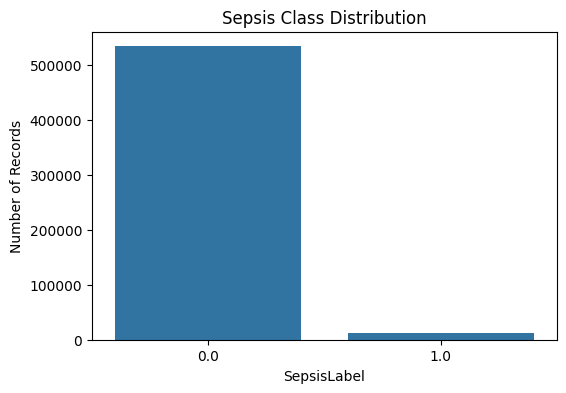

In [7]:
#Target variable analysis
target = 'SepsisLabel'

print(df[target].value_counts())
print("\nPercentage:")
print(df[target].value_counts(normalize=True) * 100)

print()
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=target)

plt.title("Sepsis Class Distribution")
plt.xlabel("SepsisLabel")
plt.ylabel("Number of Records")

plt.show()

In [8]:
# Distribution of physiological variables

# variables we're looking into mainly
vital_signs = [
    'HR',
    'SBP',
    'DBP',
    'MAP',
    'Temp',
    'O2Sat',
    'Resp'
]

# Keep only columns that actually exist
vital_signs = [col for col in vital_signs if col in df.columns]

print("Available vital signs:", vital_signs)

Available vital signs: ['HR', 'SBP', 'DBP', 'MAP', 'Temp', 'O2Sat', 'Resp']


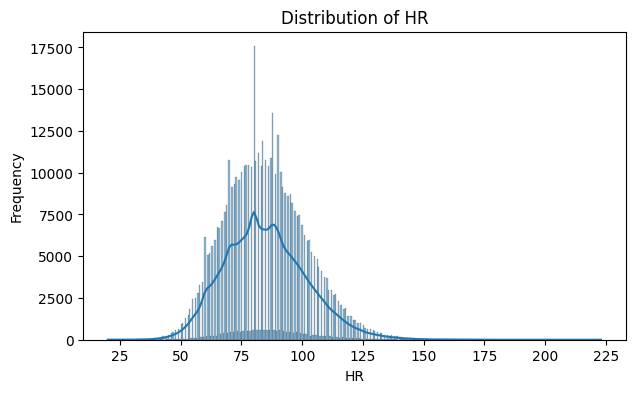

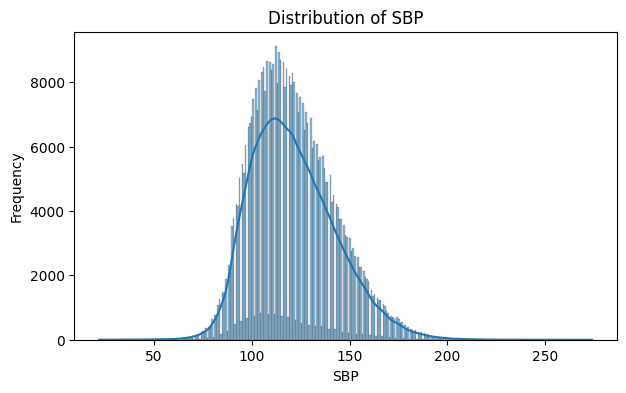

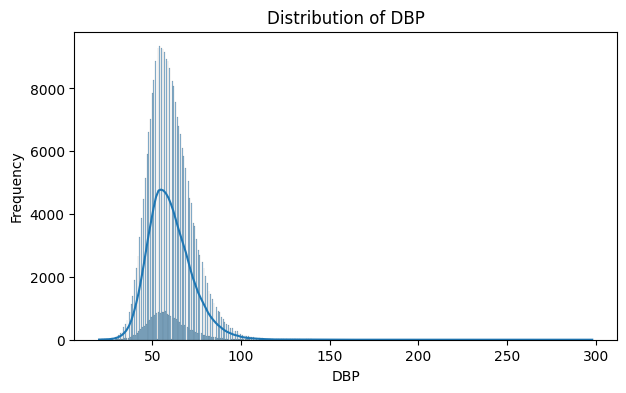

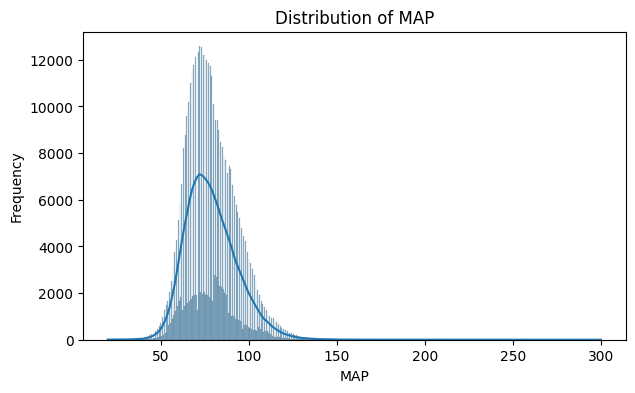

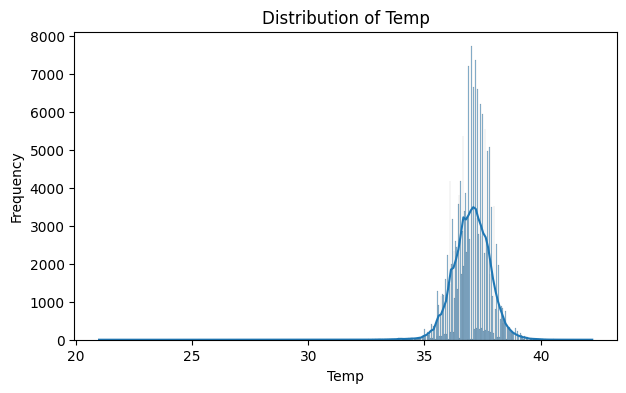

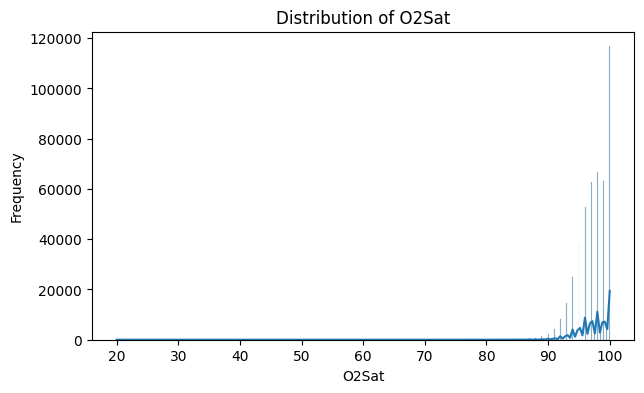

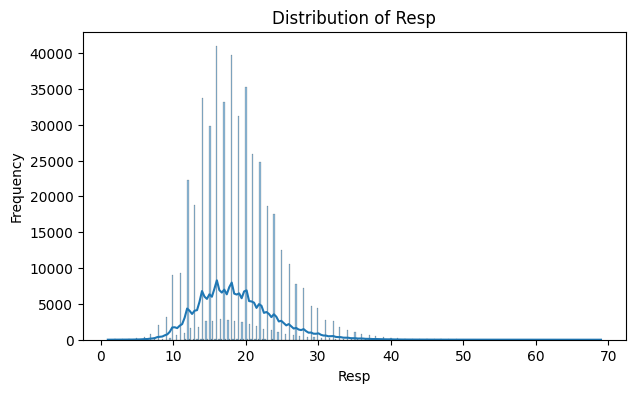

In [ ]:
# histogram
for col in vital_signs:

    plt.figure(figsize=(7, 4))

    sns.histplot(df[col].dropna(), kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

    print()

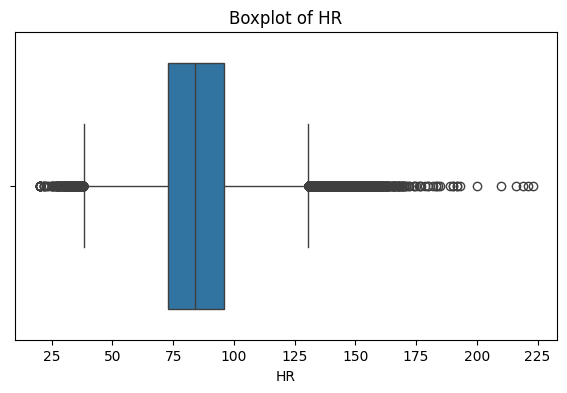

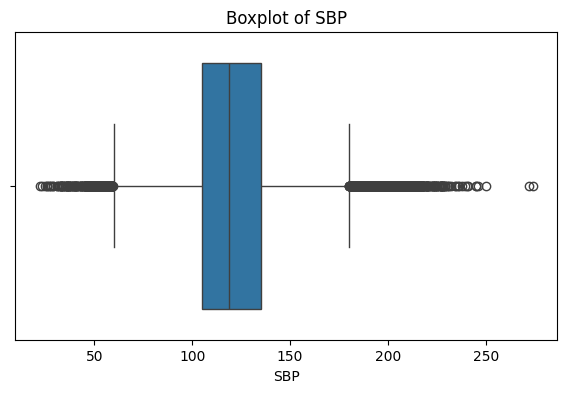

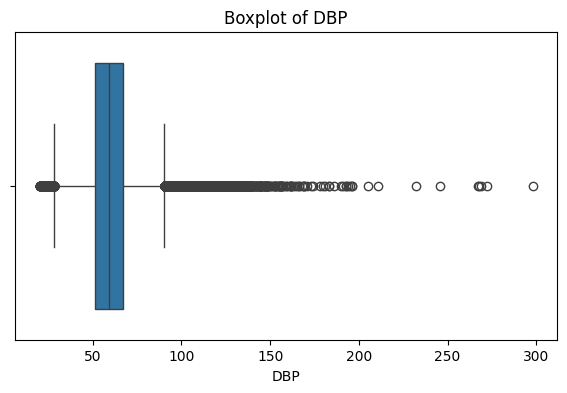

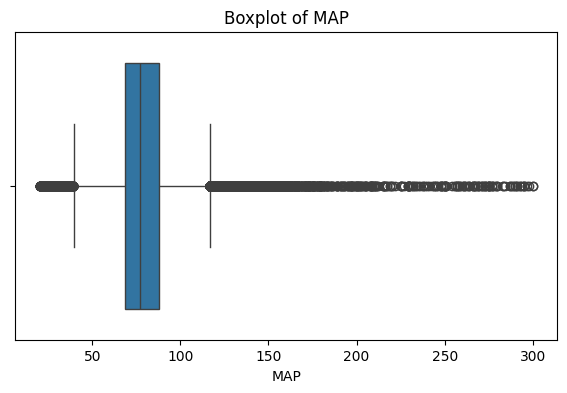

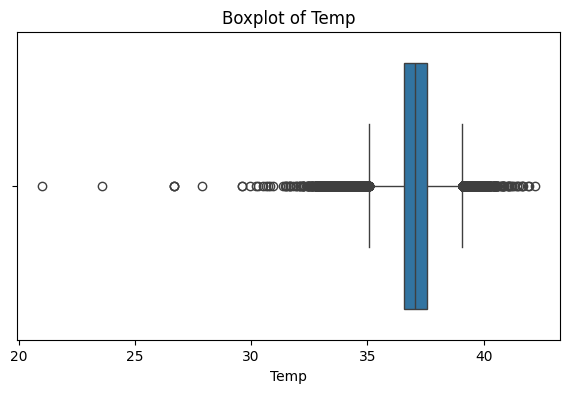

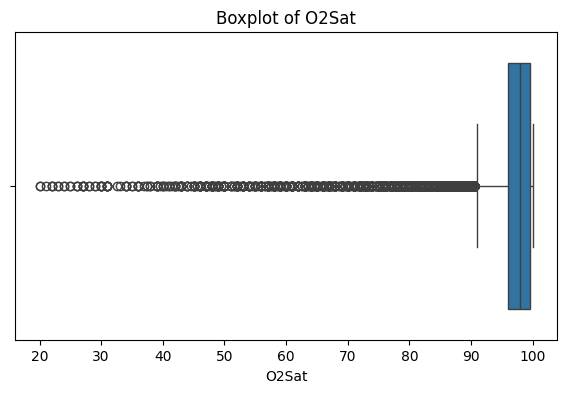

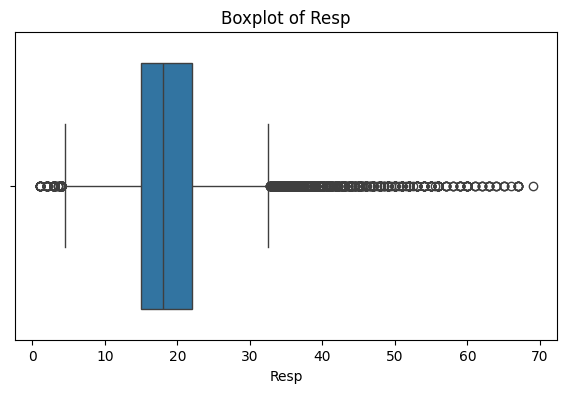

In [ ]:
# Boxplots and outlier detection
for col in vital_signs:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()
    print()

In [9]:
outlier_summary = []

for col in vital_signs:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': outliers,
        'Outlier %': outliers / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,HR,38.50,130.50,4768,0.873063
1,SBP,60.00,180.00,4212,0.771255
2,DBP,28.25,90.25,5789,1.060018
3,MAP,39.32,116.68,7624,1.396023
4,Temp,35.06,39.06,2758,0.505014
5,O2Sat,90.75,104.75,7976,1.460477
6,Resp,4.50,32.50,8539,1.563567


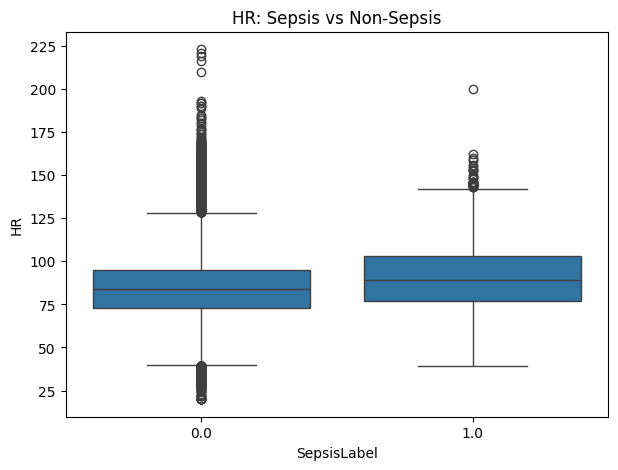

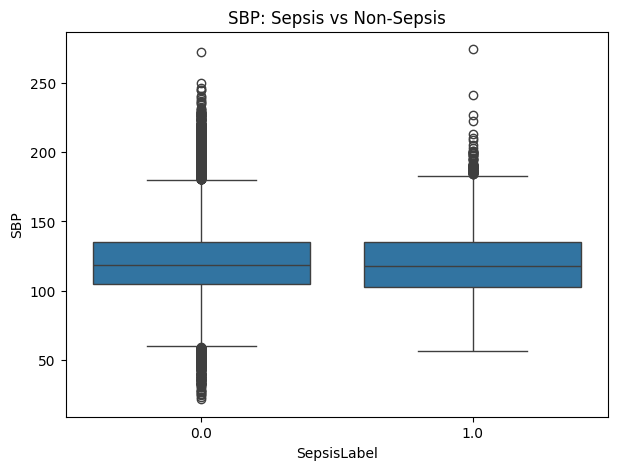

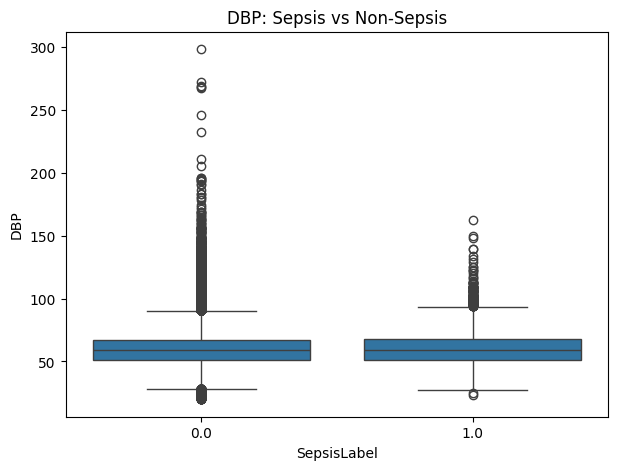

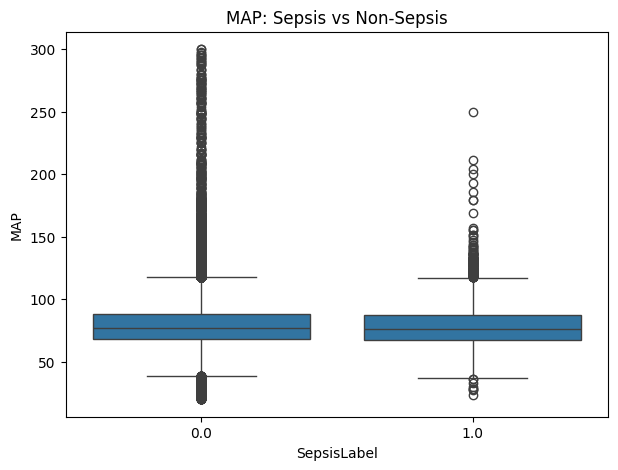

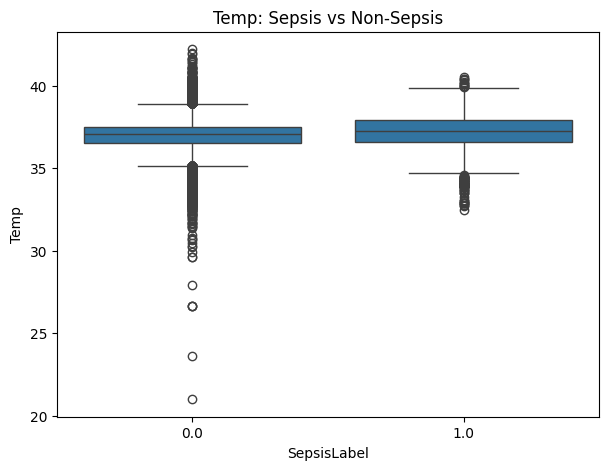

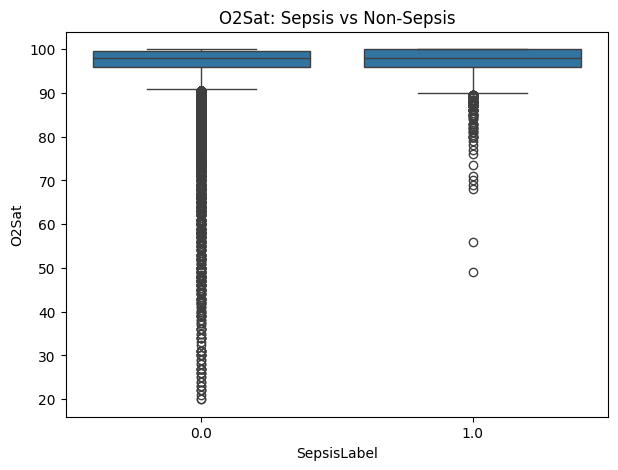

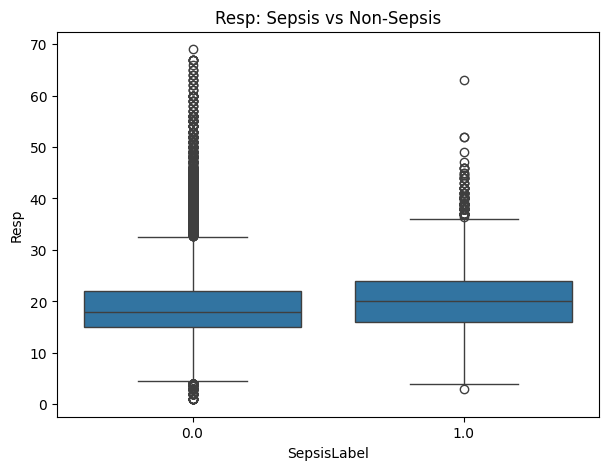

In [ ]:
#Compare vital signs between sepsis and non-sepsis
for col in vital_signs:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y=col
    )

    plt.title(f"{col}: Sepsis vs Non-Sepsis")

    plt.show()
    print()

In [10]:
# compare means
comparison = df.groupby(target)[vital_signs].agg(['mean', 'median', 'std'])

display(comparison)

HR                           SBP                    \
                  mean median        std        mean median        std   
SepsisLabel                                                              
0.0          84.815481   84.0  16.878573  121.114769  119.0  21.475409   
1.0          90.340042   89.0  18.445925  120.281716  118.0  22.900371   

                   DBP                          MAP  ...             \
                  mean median        std       mean  ...        std   
SepsisLabel                                          ...              
0.0          60.085895   59.0  12.580839  78.878582  ...  15.042322   
1.0          60.752597   59.0  13.774288  78.280714  ...  15.713046   

                  Temp                       O2Sat                   \
                  mean median       std       mean median       std   
SepsisLabel                                                           
0.0          37.023917  37.06  0.776659  97.259694   98.0  2.937009   
1.0          37.235699  37.28  1.032269  97.209349   98.0  2.857988   

                  Resp                   
                  mean median       std  
SepsisLabel                              
0.0          18.705249   18.0  5.355854  
1.0          20.696300   20.0  6.040000  

[2 rows x 21 columns]

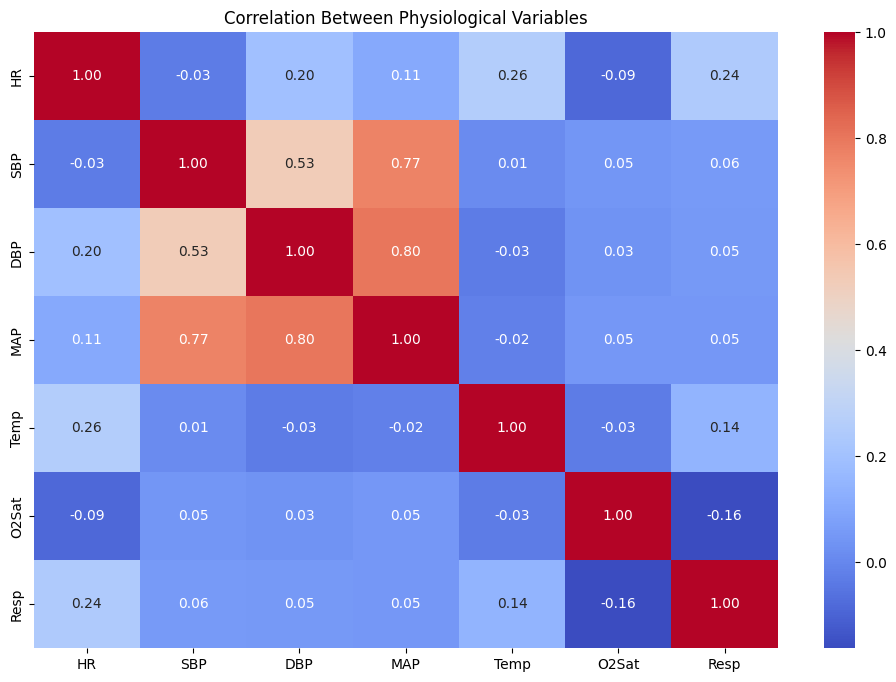

In [11]:
#Correlation analysis
plt.figure(figsize=(12, 8))

corr = df[vital_signs].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Physiological Variables")

plt.show()

In [12]:
#Temporal analysis
time_col = 'Hour'
patient_col = 'Patient_ID'

df = df.sort_values([patient_col, time_col]).reset_index(drop=True)
#display(df)

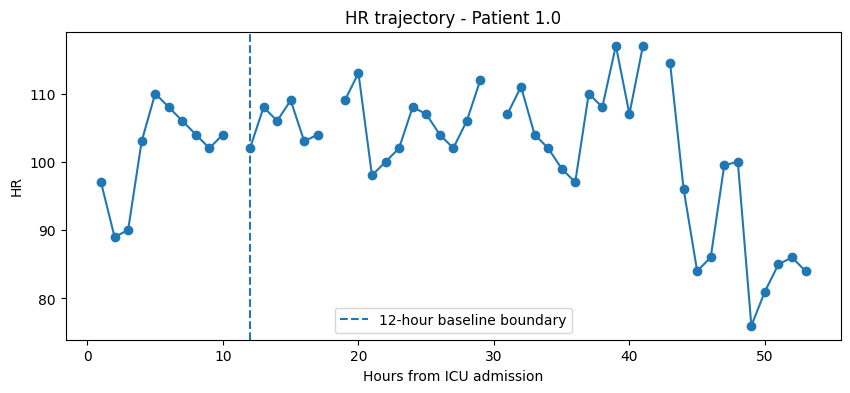

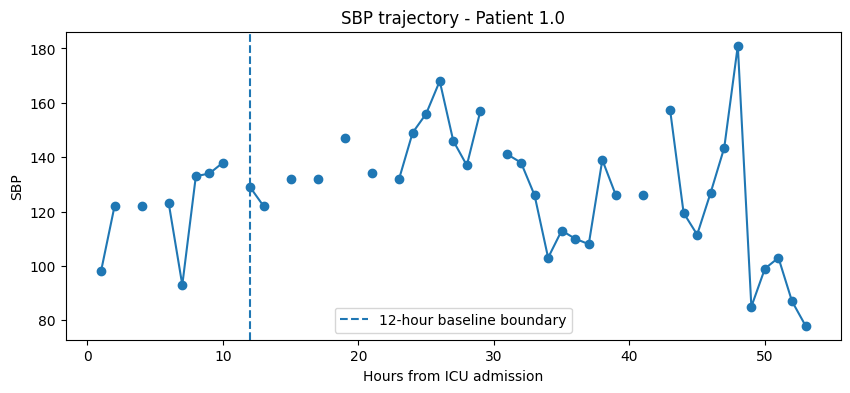

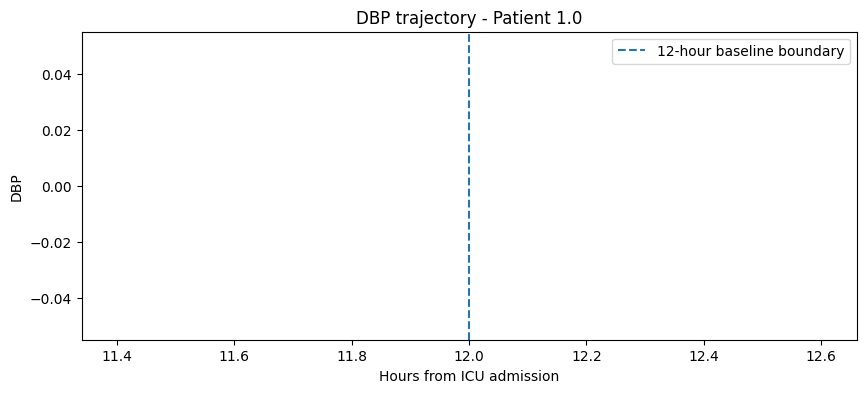

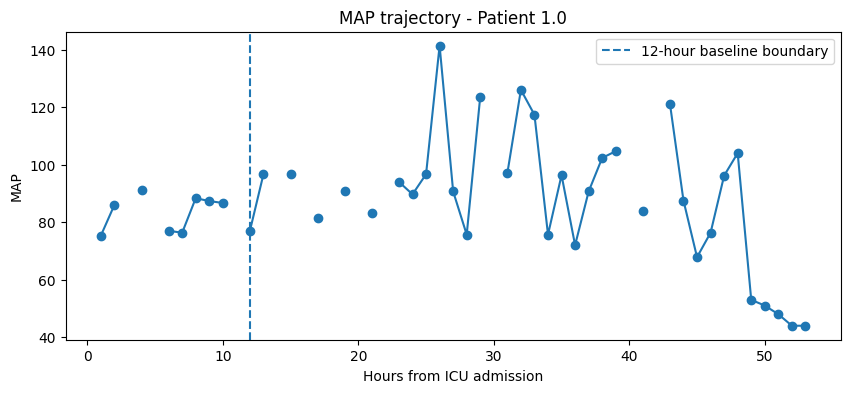

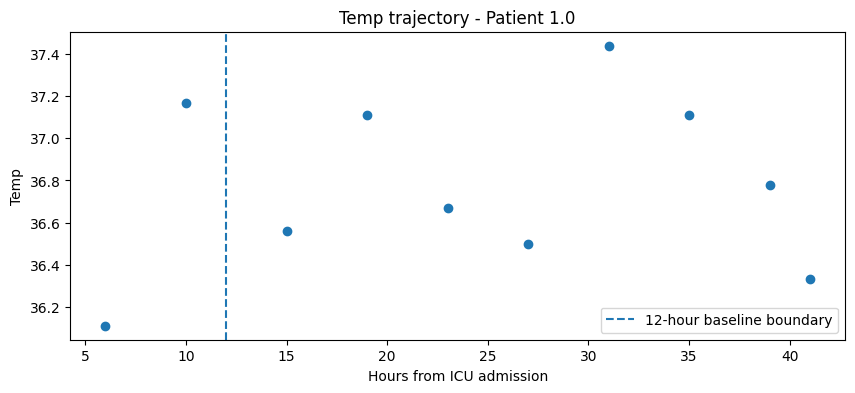

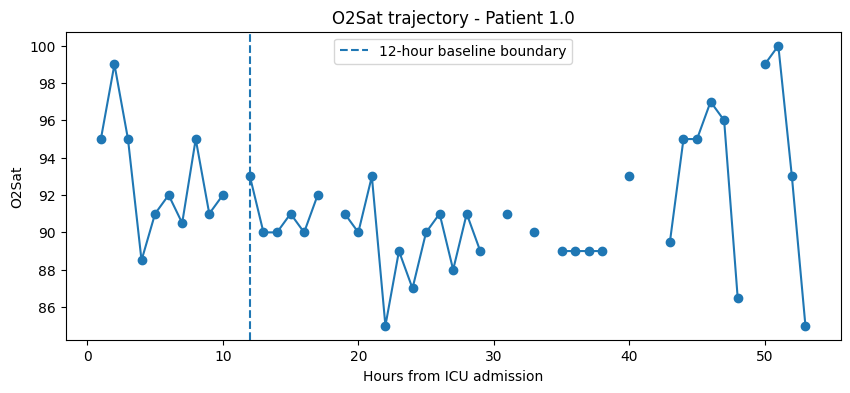

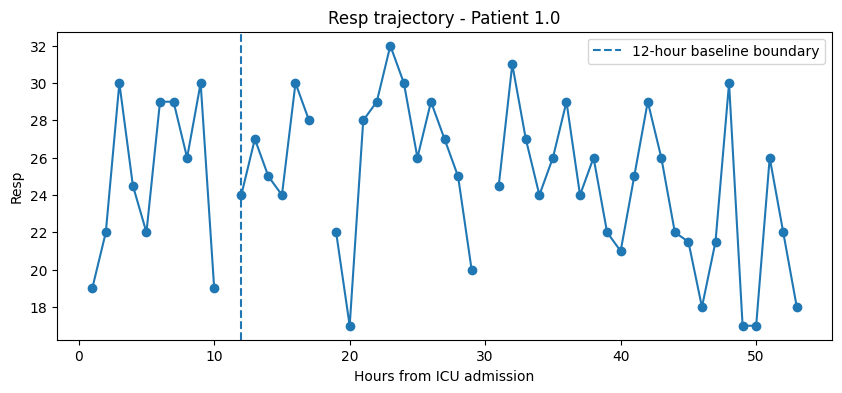

In [13]:
#Plot an individual patient's physiological trajectory
patient_id = df[patient_col].iloc[0]

patient = df[df[patient_col] == patient_id]

for col in vital_signs:

    plt.figure(figsize=(10, 4))

    plt.plot(
        patient['Hour'],
        patient[col],
        marker='o'
    )

    plt.xlabel("Hours from ICU admission")
    plt.ylabel(col)

    plt.title(f"{col} trajectory - Patient {patient_id}")

    plt.axvline(
        x=12,
        linestyle='--',
        label='12-hour baseline boundary'
    )

    plt.legend()

    plt.show()
    print()

In [14]:
# Define the three temporal windows for the refined project
# 0-12 h: patient-specific baseline
# 12-24 h: observation/deviation window
# 24-48 h: future prediction/outcome window

baseline_period = df[
    (df[time_col] >= 0) &
    (df[time_col] < 12)
].copy()

observation_window = df[
    (df[time_col] >= 12) &
    (df[time_col] < 24)
].copy()

outcome_window = df[
    (df[time_col] >= 24) &
    (df[time_col] < 48)
].copy()

print("Baseline window (0-12 h):", baseline_period[time_col].min(), "to", baseline_period[time_col].max())
print("Observation window (12-24 h):", observation_window[time_col].min(), "to", observation_window[time_col].max())
print("Outcome window (24-48 h):", outcome_window[time_col].min(), "to", outcome_window[time_col].max())


Baseline window (0-12 h): 0 to 11
Observation window (12-24 h): 12 to 23
Outcome window (24-48 h): 24 to 47


In [15]:
baseline = (
    baseline_period
    .groupby(patient_col)[vital_signs]
    .median()
    .add_suffix('_baseline')
)

display(baseline.head())

,HR_baseline,SBP_baseline,DBP_baseline,MAP_baseline,Temp_baseline,O2Sat_baseline,Resp_baseline
Patient_ID,,,,,,,
1.0,103.5,122.50,NaN,86.335,36.64,92.0,25.25
2.0,60.0,126.00,43.0,67.000,36.22,99.0,13.00
4.0,95.0,116.00,52.0,72.000,36.39,98.5,18.00
5.0,73.0,136.00,NaN,87.500,37.25,97.0,17.00
8.0,78.0,103.75,51.0,65.000,36.50,100.0,18.00


In [35]:
#merging
df = df.merge(
    baseline,
    on=patient_col,
    how='left'
)


In [36]:
# calculate deviation from baseline
for col in vital_signs:

    baseline_col = col + '_baseline'

    df[col + '_deviation'] = (
        df[col] - df[baseline_col]
    )

print()
# percentage
for col in vital_signs:

    baseline_col = col + '_baseline'

    denominator = df[baseline_col].replace(0, np.nan)

    df[col + '_pct_deviation'] = (
        (df[col] - df[baseline_col])
        / denominator
    ) * 100

In [37]:
# BUG FIX: observation_window was sliced from df *before* the baseline/deviation
# columns above were added, so it was silently missing them -- this is what was
# throwing the KeyError. Re-slice from the updated df now that those columns exist.
observation_window = df[
    (df[time_col] >= 12) &
    (df[time_col] < 24)
].copy()


In [38]:
# Analyze deviations during the 12-24 hour observation window
deviation_cols = [col + '_deviation' for col in vital_signs]

display(
    observation_window[deviation_cols].describe().T
)


,count,mean,std,min,25%,50%,75%,max
HR_deviation,140237.0,0.127802,11.610801,-115.00,-6.25,0.00,6.0,149.00
SBP_deviation,128906.0,1.567179,16.386570,-159.00,-8.00,1.00,11.0,114.75
DBP_deviation,76772.0,-0.325951,9.537164,-65.50,-6.00,-1.00,4.5,158.00
MAP_deviation,136263.0,0.347267,12.097522,-75.00,-6.83,0.00,7.0,233.00
Temp_deviation,52276.0,0.179260,0.706021,-6.73,-0.22,0.16,0.6,4.89
O2Sat_deviation,133299.0,-0.851132,2.702605,-79.00,-2.00,-0.50,0.0,40.00
Resp_deviation,136813.0,0.979853,4.729508,-29.50,-2.00,0.50,3.5,48.00


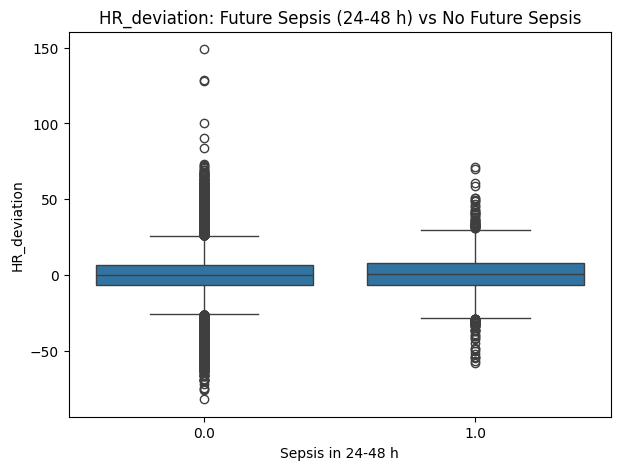

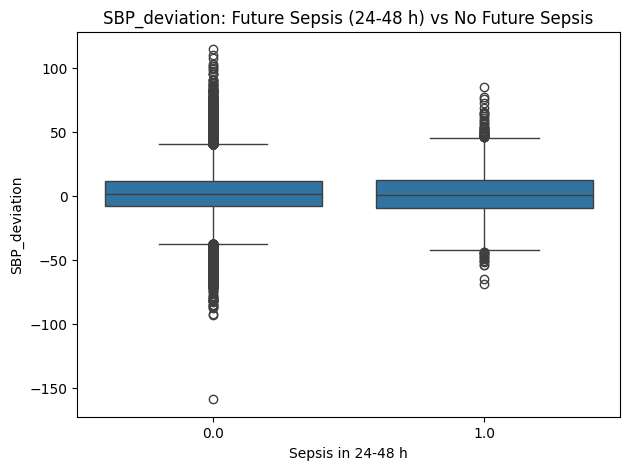

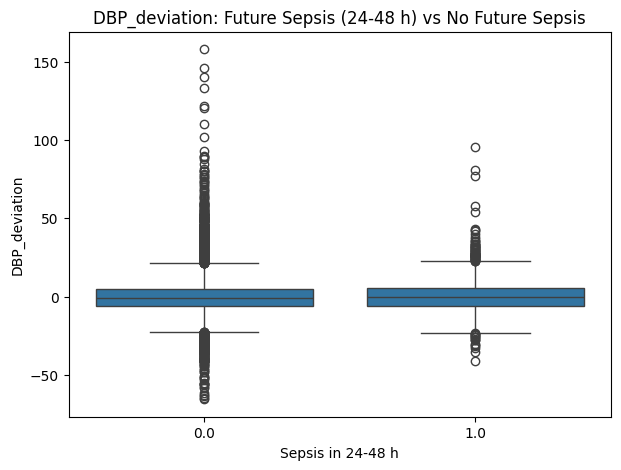

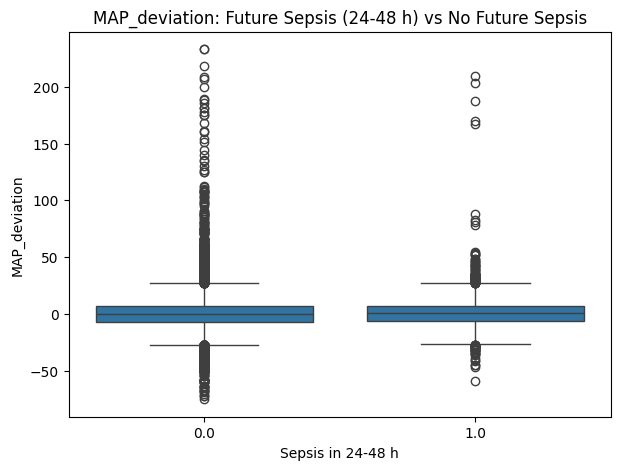

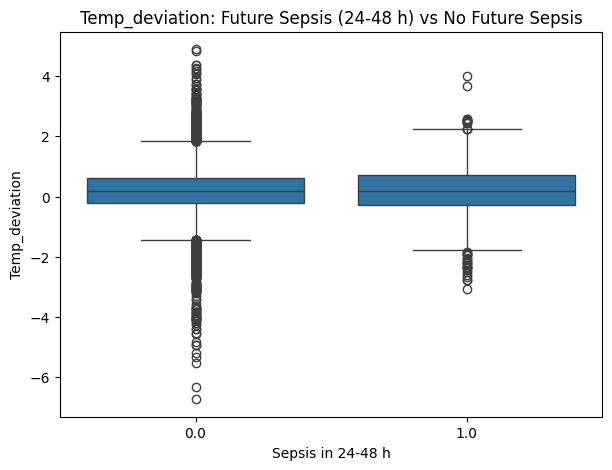

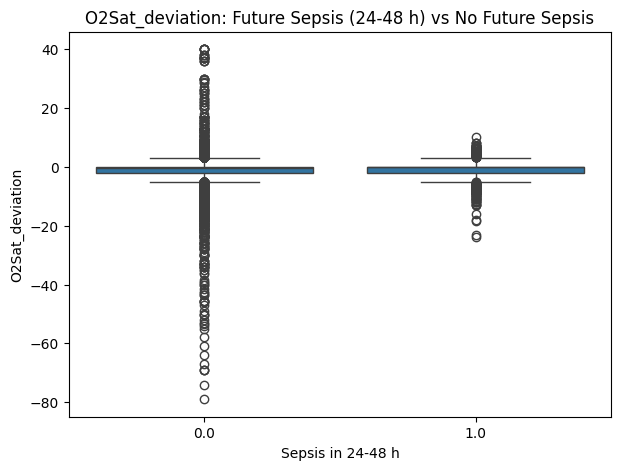

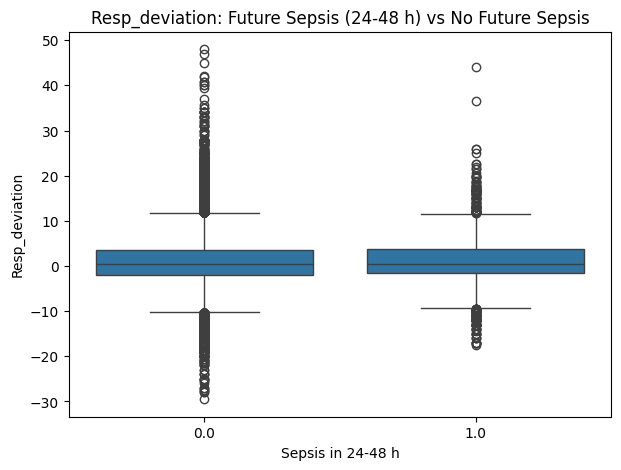

In [39]:
# Compare personalized deviations between patients who do and do not develop sepsis in 24-48 h
# Target is added later after patient-level aggregation.

# Temporary target for visualization only: whether sepsis occurs in 24-48 h
outcome_target = (
    outcome_window.groupby(patient_col)[target]
    .max()
    .rename('FutureSepsis')
)

deviation_plot_data = observation_window.merge(
    outcome_target,
    on=patient_col,
    how='inner'
)

for col in deviation_cols:
    plt.figure(figsize=(7, 5))
    sns.boxplot(
        data=deviation_plot_data,
        x='FutureSepsis',
        y=col
    )
    plt.title(f"{col}: Future Sepsis (24-48 h) vs No Future Sepsis")
    plt.xlabel("Sepsis in 24-48 h")
    plt.show()
    print()


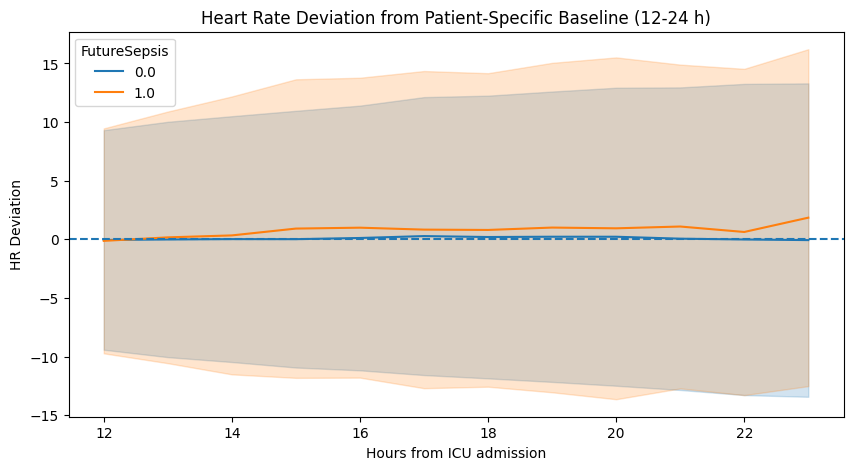

In [40]:
# Plot HR deviation over the 12-24 hour observation window
plot_data = observation_window.merge(
    outcome_target,
    on=patient_col,
    how='inner'
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=plot_data,
    x='Hour',
    y='HR_deviation',
    hue='FutureSepsis',
    errorbar='sd'
)
plt.axhline(0, linestyle='--')
plt.title("Heart Rate Deviation from Patient-Specific Baseline (12-24 h)")
plt.xlabel("Hours from ICU admission")
plt.ylabel("HR Deviation")
plt.show()


In [41]:
# Patient-level deviation summaries for the 12-24 h observation window
max_deviation = (
    observation_window
    .groupby(patient_col)[deviation_cols]
    .max()
)

mean_deviation = (
    observation_window
    .groupby(patient_col)[deviation_cols]
    .mean()
)

std_deviation = (
    observation_window
    .groupby(patient_col)[deviation_cols]
    .std()
)

display(max_deviation.head())


,HR_deviation,SBP_deviation,DBP_deviation,MAP_deviation,Temp_deviation,O2Sat_deviation,Resp_deviation
Patient_ID,,,,,,,
1.0,9.5,24.50,NaN,10.335,0.47,1.0,6.75
2.0,3.0,28.00,3.0,14.000,-0.11,-1.0,5.00
4.0,12.0,9.00,-0.5,1.000,0.00,1.5,6.00
5.0,14.0,7.00,NaN,5.500,-0.03,2.0,4.00
8.0,10.0,16.25,0.0,8.000,0.17,0.0,1.00


In [42]:
#Analyze rate of change

df = df.sort_values([patient_col, 'Hour'])

for col in vital_signs:

    df[col + '_change'] = (
        df.groupby(patient_col)[col]
          .diff()
    )

In [43]:
# BUG FIX (part 2): refresh again now that the *_change columns exist too, so
# prediction_window (built from observation_window below) has every feature
# column the patient-level aggregation step needs.
observation_window = df[
    (df[time_col] >= 12) &
    (df[time_col] < 24)
].copy()


In [44]:
#Missingness by sepsis status
for col in vital_signs:

    missing_rate = (
        df.groupby(target)[col]
          .apply(lambda x: x.isnull().mean() * 100)
    )

    print(f"\n{col}")
    print(missing_rate)
    print()


HR
SepsisLabel
0.0    7.730894
1.0    6.911392
Name: HR, dtype: float64


SBP
SepsisLabel
0.0    15.179721
1.0    17.738397
Name: SBP, dtype: float64


DBP
SepsisLabel
0.0    48.015430
1.0    41.510549
Name: DBP, dtype: float64


MAP
SepsisLabel
0.0    10.220075
1.0     8.379747
Name: MAP, dtype: float64


Temp
SepsisLabel
0.0    66.162928
1.0    68.531646
Name: Temp, dtype: float64


O2Sat
SepsisLabel
0.0    12.094589
1.0    10.008439
Name: O2Sat, dtype: float64


Resp
SepsisLabel
0.0    9.817097
1.0    8.421941
Name: Resp, dtype: float64



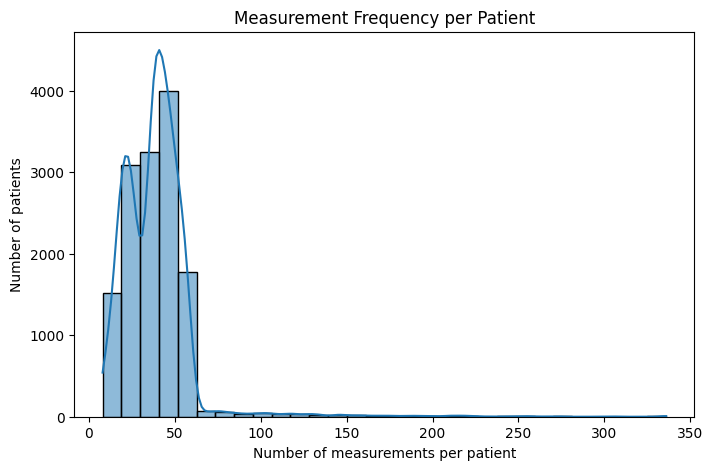

In [45]:
#Measurement frequency
measurement_counts = (
    df.groupby(patient_col)
      .size()
)

plt.figure(figsize=(8, 5))

sns.histplot(
    measurement_counts,
    bins=30,
    kde=True
)

plt.xlabel("Number of measurements per patient")
plt.ylabel("Number of patients")

plt.title("Measurement Frequency per Patient")

plt.show()

In [46]:
#Final personalized feature dataset
features = []

for col in vital_signs:

    features.extend([
        col + '_baseline',
        col + '_deviation',
        col + '_pct_deviation',
        col + '_change'
    ])

print(features)

['HR_baseline', 'HR_deviation', 'HR_pct_deviation', 'HR_change', 'SBP_baseline', 'SBP_deviation', 'SBP_pct_deviation', 'SBP_change', 'DBP_baseline', 'DBP_deviation', 'DBP_pct_deviation', 'DBP_change', 'MAP_baseline', 'MAP_deviation', 'MAP_pct_deviation', 'MAP_change', 'Temp_baseline', 'Temp_deviation', 'Temp_pct_deviation', 'Temp_change', 'O2Sat_baseline', 'O2Sat_deviation', 'O2Sat_pct_deviation', 'O2Sat_change', 'Resp_baseline', 'Resp_deviation', 'Resp_pct_deviation', 'Resp_change']


In [47]:
# Patient-level FEATURE Aggregation

prediction_window = observation_window.copy()


feature_data = []

for patient_id, group in prediction_window.groupby(patient_col):

    row = {
        patient_col: patient_id
    }

    for col in vital_signs:

        # Baseline
        baseline_col = col + '_baseline'

        row[col + '_baseline'] = group[baseline_col].iloc[0]

        # Deviation statistics
        deviation_col = col + '_deviation'

        row[col + '_dev_mean'] = group[deviation_col].mean()
        row[col + '_dev_std'] = group[deviation_col].std()
        row[col + '_dev_max'] = group[deviation_col].max()
        row[col + '_dev_min'] = group[deviation_col].min()

        # Absolute deviation
        row[col + '_abs_dev_mean'] = (
            group[deviation_col].abs().mean()
        )

        row[col + '_abs_dev_max'] = (
            group[deviation_col].abs().max()
        )

        # Percentage deviation
        pct_col = col + '_pct_deviation'

        row[col + '_pct_dev_mean'] = group[pct_col].mean()
        row[col + '_pct_dev_max'] = group[pct_col].max()

        # Rate of change
        change_col = col + '_change'

        row[col + '_change_mean'] = group[change_col].mean()
        row[col + '_change_std'] = group[change_col].std()
        row[col + '_change_max'] = group[change_col].max()
        row[col + '_change_min'] = group[change_col].min()

    feature_data.append(row)


patient_features = pd.DataFrame(feature_data)

print("Patient-level feature dataset:")
print(patient_features.shape)

display(patient_features.head())

Patient-level feature dataset:
(13655, 92)


,Patient_ID,HR_baseline,HR_dev_mean,HR_dev_std,HR_dev_max,HR_dev_min,HR_abs_dev_mean,HR_abs_dev_max,HR_pct_dev_mean,HR_pct_dev_max,...,Resp_dev_max,Resp_dev_min,Resp_abs_dev_mean,Resp_abs_dev_max,Resp_pct_dev_mean,Resp_pct_dev_max,Resp_change_mean,Resp_change_std,Resp_change_max,Resp_change_min
0,1.0,103.5,1.409091,4.504543,9.5,-5.5,3.681818,9.5,1.361440,9.178744,...,6.75,-8.25,3.340909,8.25,2.970297,26.732673,1.555556,4.850544,11.0,-5.0
1,2.0,60.0,-1.363636,3.828126,3.0,-6.0,3.545455,6.0,-2.272727,5.000000,...,5.00,-3.00,2.375000,5.00,-2.884615,38.461538,-0.428571,3.408672,4.0,-7.0
2,4.0,95.0,7.000000,4.612237,12.0,-1.0,7.166667,12.0,7.368421,12.631579,...,6.00,-3.00,2.681818,6.00,2.272727,33.333333,-0.800000,4.230839,6.0,-6.0
3,5.0,73.0,0.666667,8.660254,14.0,-12.0,6.444444,14.0,0.913242,19.178082,...,4.00,-3.00,2.111111,4.00,-5.882353,23.529412,0.714286,1.603567,3.0,-1.0
4,8.0,78.0,2.583333,6.921092,10.0,-6.0,6.750000,10.0,3.311966,12.820513,...,1.00,-6.00,2.166667,6.00,-11.111111,5.555556,0.000000,2.593699,5.0,-4.0


In [48]:
# Define the final patient cohort and future target

# A patient is eligible only if all three required windows are present:
# 0-12 h baseline, 12-24 h observation, and 24-48 h outcome.
baseline_counts = baseline_period.groupby(patient_col).size()
observation_counts = observation_window.groupby(patient_col).size()
outcome_counts = outcome_window.groupby(patient_col).size()

eligible_patients = sorted(
    set(baseline_counts[baseline_counts > 0].index)
    & set(observation_counts[observation_counts > 0].index)
    & set(outcome_counts[outcome_counts > 0].index)
)

print("Total unique patients:", df[patient_col].nunique())
print("Eligible patients:", len(eligible_patients))
print("Excluded patients:", df[patient_col].nunique() - len(eligible_patients))

# Keep only eligible patients in the feature dataset
patient_features = patient_features[
    patient_features[patient_col].isin(eligible_patients)
].copy()

# Future target: sepsis occurring during 24-48 h
target_data = (
    outcome_window[
        outcome_window[patient_col].isin(eligible_patients)
    ]
    .groupby(patient_col)[target]
    .max()
    .reset_index()
    .rename(columns={target: 'Target'})
)

patient_features = patient_features.merge(
    target_data,
    on=patient_col,
    how='inner'
)

patient_features['Target'] = patient_features['Target'].astype(int)

print("\nFinal target distribution:")
print(patient_features['Target'].value_counts())
print("\nFinal target percentage:")
print((patient_features['Target'].value_counts(normalize=True) * 100).round(2))


Total unique patients: 14057
Eligible patients: 10607
Excluded patients: 3450

Final target distribution:
Target
0    10292
1      315
Name: count, dtype: int64

Final target percentage:
Target
0    97.03
1     2.97
Name: proportion, dtype: float64


In [49]:
# Check whether sepsis already existed before the prediction window
# This is useful because the study is about predicting FUTURE sepsis.

pre_prediction_sepsis = (
    df[
        (df[time_col] >= 0) &
        (df[time_col] < 24)
    ]
    .groupby(patient_col)[target]
    .max()
    .rename('SepsisBefore24h')
)

print("Patients with sepsis before 24 h:")
print(pre_prediction_sepsis.value_counts())

print("\nAmong eligible patients:")
print(
    pre_prediction_sepsis[
        pre_prediction_sepsis.index.isin(eligible_patients)
    ].value_counts()
)


Patients with sepsis before 24 h:
SepsisBefore24h
0.0    13486
1.0      571
Name: count, dtype: int64

Among eligible patients:
SepsisBefore24h
0.0    10499
1.0      108
Name: count, dtype: int64


In [50]:
# First recorded sepsis hour (EDA)
first_sepsis = (
    df[df[target] == 1]
    .groupby(patient_col)[time_col]
    .min()
)

print(first_sepsis.describe())

print("\nFirst sepsis hour distribution:")
print(first_sepsis.value_counts().sort_index())


count    1239.000000
mean       49.032284
std        56.348577
min         0.000000
25%         7.000000
50%        29.000000
75%        71.000000
max       330.000000
Name: Hour, dtype: float64

First sepsis hour distribution:
Hour
0      137
1       33
2       32
3       24
4       27
      ... 
266      1
287      1
295      1
296      1
330      1
Name: count, Length: 209, dtype: int64


In [51]:
# Final target distribution after applying the temporal eligibility criteria
print("Final patient-level dataset shape:", patient_features.shape)

print("\nTarget counts:")
print(patient_features['Target'].value_counts())

print("\nTarget percentages:")
print((patient_features['Target'].value_counts(normalize=True) * 100).round(2))


Final patient-level dataset shape: (10607, 93)

Target counts:
Target
0    10292
1      315
Name: count, dtype: int64

Target percentages:
Target
0    97.03
1     2.97
Name: proportion, dtype: float64


In [52]:
# Conventional feature dataset for comparison
# Conventional features use raw measurements from 12-24 h rather than patient-specific deviations.

conventional_rows = []

for patient_id, group in observation_window.groupby(patient_col):
    if patient_id not in eligible_patients:
        continue

    row = {patient_col: patient_id}

    for col in vital_signs:
        row[f'{col}_raw_mean'] = group[col].mean()
        row[f'{col}_raw_std'] = group[col].std()
        row[f'{col}_raw_max'] = group[col].max()
        row[f'{col}_raw_min'] = group[col].min()

    conventional_rows.append(row)

conventional_features = pd.DataFrame(conventional_rows)

conventional_features = conventional_features.merge(
    patient_features[[patient_col, 'Target']],
    on=patient_col,
    how='inner'
)

print("Conventional feature dataset:", conventional_features.shape)
display(conventional_features.head())


Conventional feature dataset: (10607, 30)


,Patient_ID,HR_raw_mean,HR_raw_std,HR_raw_max,HR_raw_min,SBP_raw_mean,SBP_raw_std,SBP_raw_max,SBP_raw_min,DBP_raw_mean,...,Temp_raw_min,O2Sat_raw_mean,O2Sat_raw_std,O2Sat_raw_max,O2Sat_raw_min,Resp_raw_mean,Resp_raw_std,Resp_raw_max,Resp_raw_min,Target
0,1.0,104.909091,4.504543,113.0,98.0,132.571429,7.480132,147.0,122.0,NaN,...,36.56,90.363636,2.203303,93.0,85.0,26.000000,4.195235,32.0,17.0,0
1,4.0,102.000000,4.612237,107.0,94.0,109.818182,7.413746,125.0,98.0,48.500000,...,36.39,97.916667,1.564279,100.0,96.0,18.409091,3.277333,24.0,15.0,0
2,5.0,73.666667,8.660254,87.0,61.0,129.555556,9.761034,143.0,114.0,NaN,...,36.94,97.714286,0.755929,99.0,97.0,16.000000,2.236068,21.0,14.0,0
3,8.0,80.583333,6.921092,88.0,72.0,107.791667,8.850933,120.0,97.0,45.416667,...,36.22,98.000000,6.015132,100.0,79.0,16.000000,2.256304,19.0,12.0,0
4,9.0,97.333333,5.305800,107.0,90.0,110.375000,7.373555,122.5,96.0,61.958333,...,36.44,94.208333,3.018566,99.0,89.5,19.354167,5.246707,35.0,16.0,0


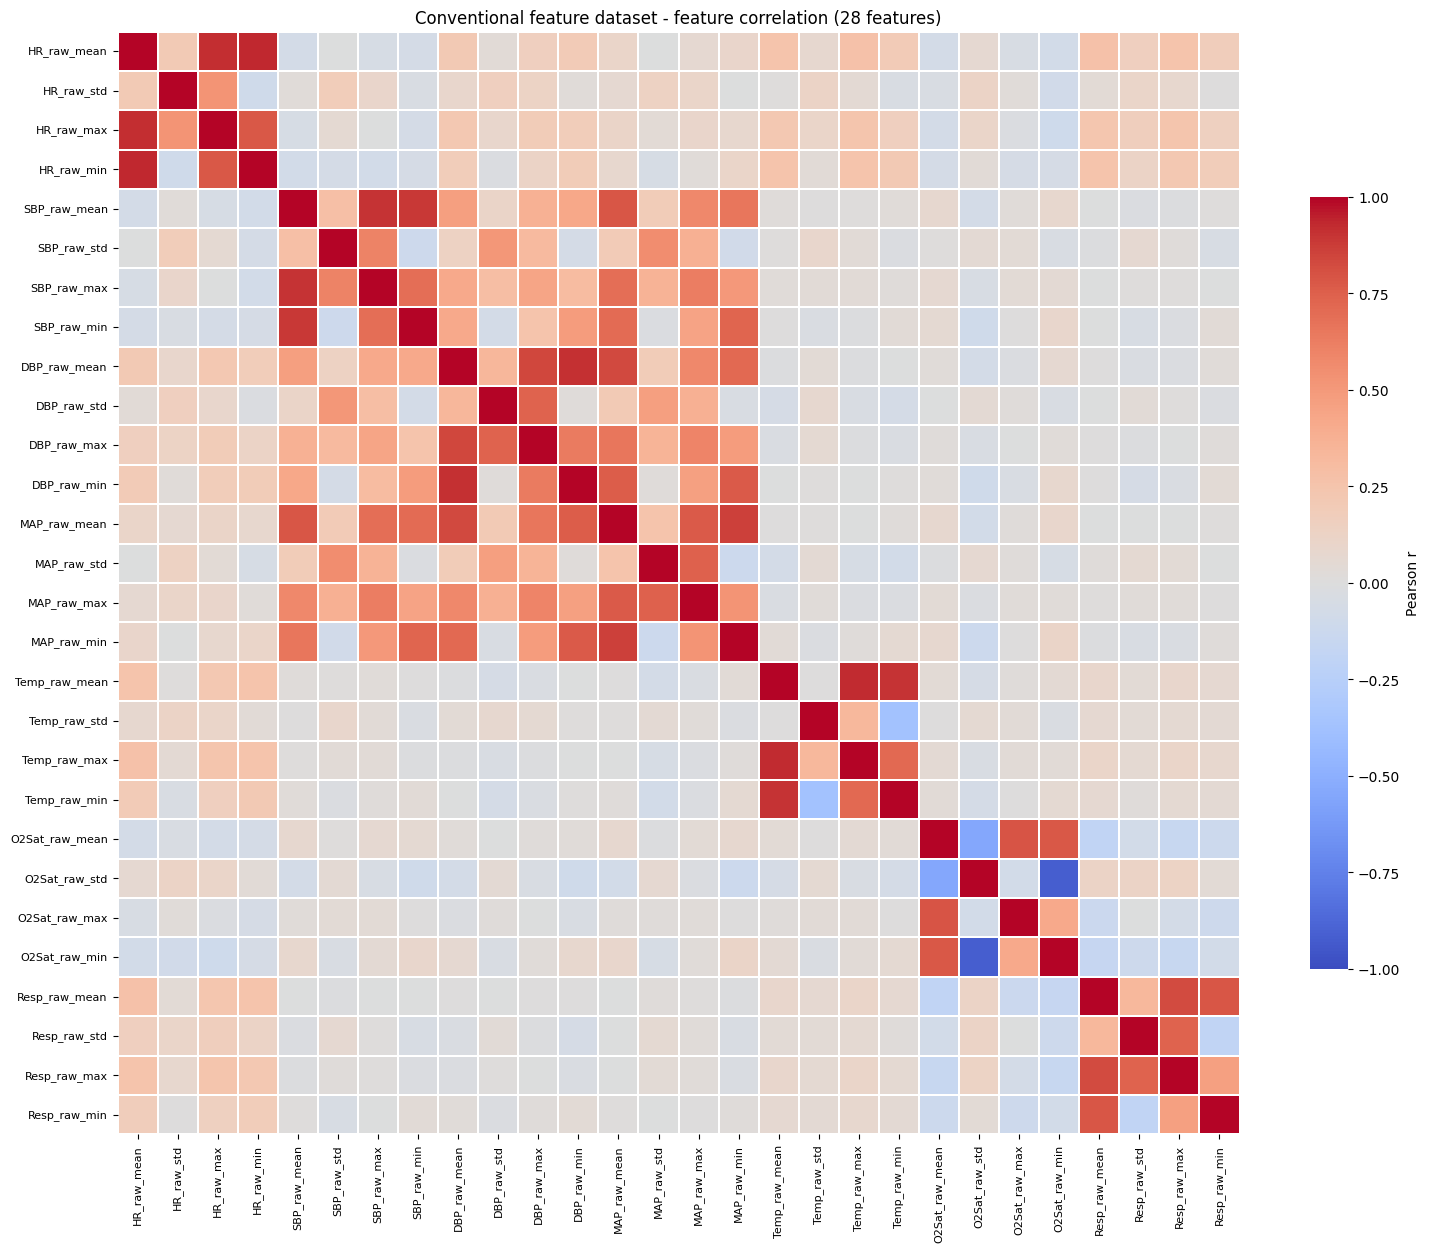

Top correlated pairs - Conventional


,Feature A,Feature B,|r|
0,HR_raw_mean,HR_raw_min,0.936
1,Temp_raw_mean,Temp_raw_max,0.930
2,HR_raw_mean,HR_raw_max,0.916
3,O2Sat_raw_std,O2Sat_raw_min,0.916
4,DBP_raw_mean,DBP_raw_min,0.909
5,SBP_raw_mean,SBP_raw_max,0.903
6,Temp_raw_mean,Temp_raw_min,0.901
7,SBP_raw_mean,SBP_raw_min,0.884
8,MAP_raw_mean,MAP_raw_min,0.864
9,DBP_raw_mean,DBP_raw_max,0.838


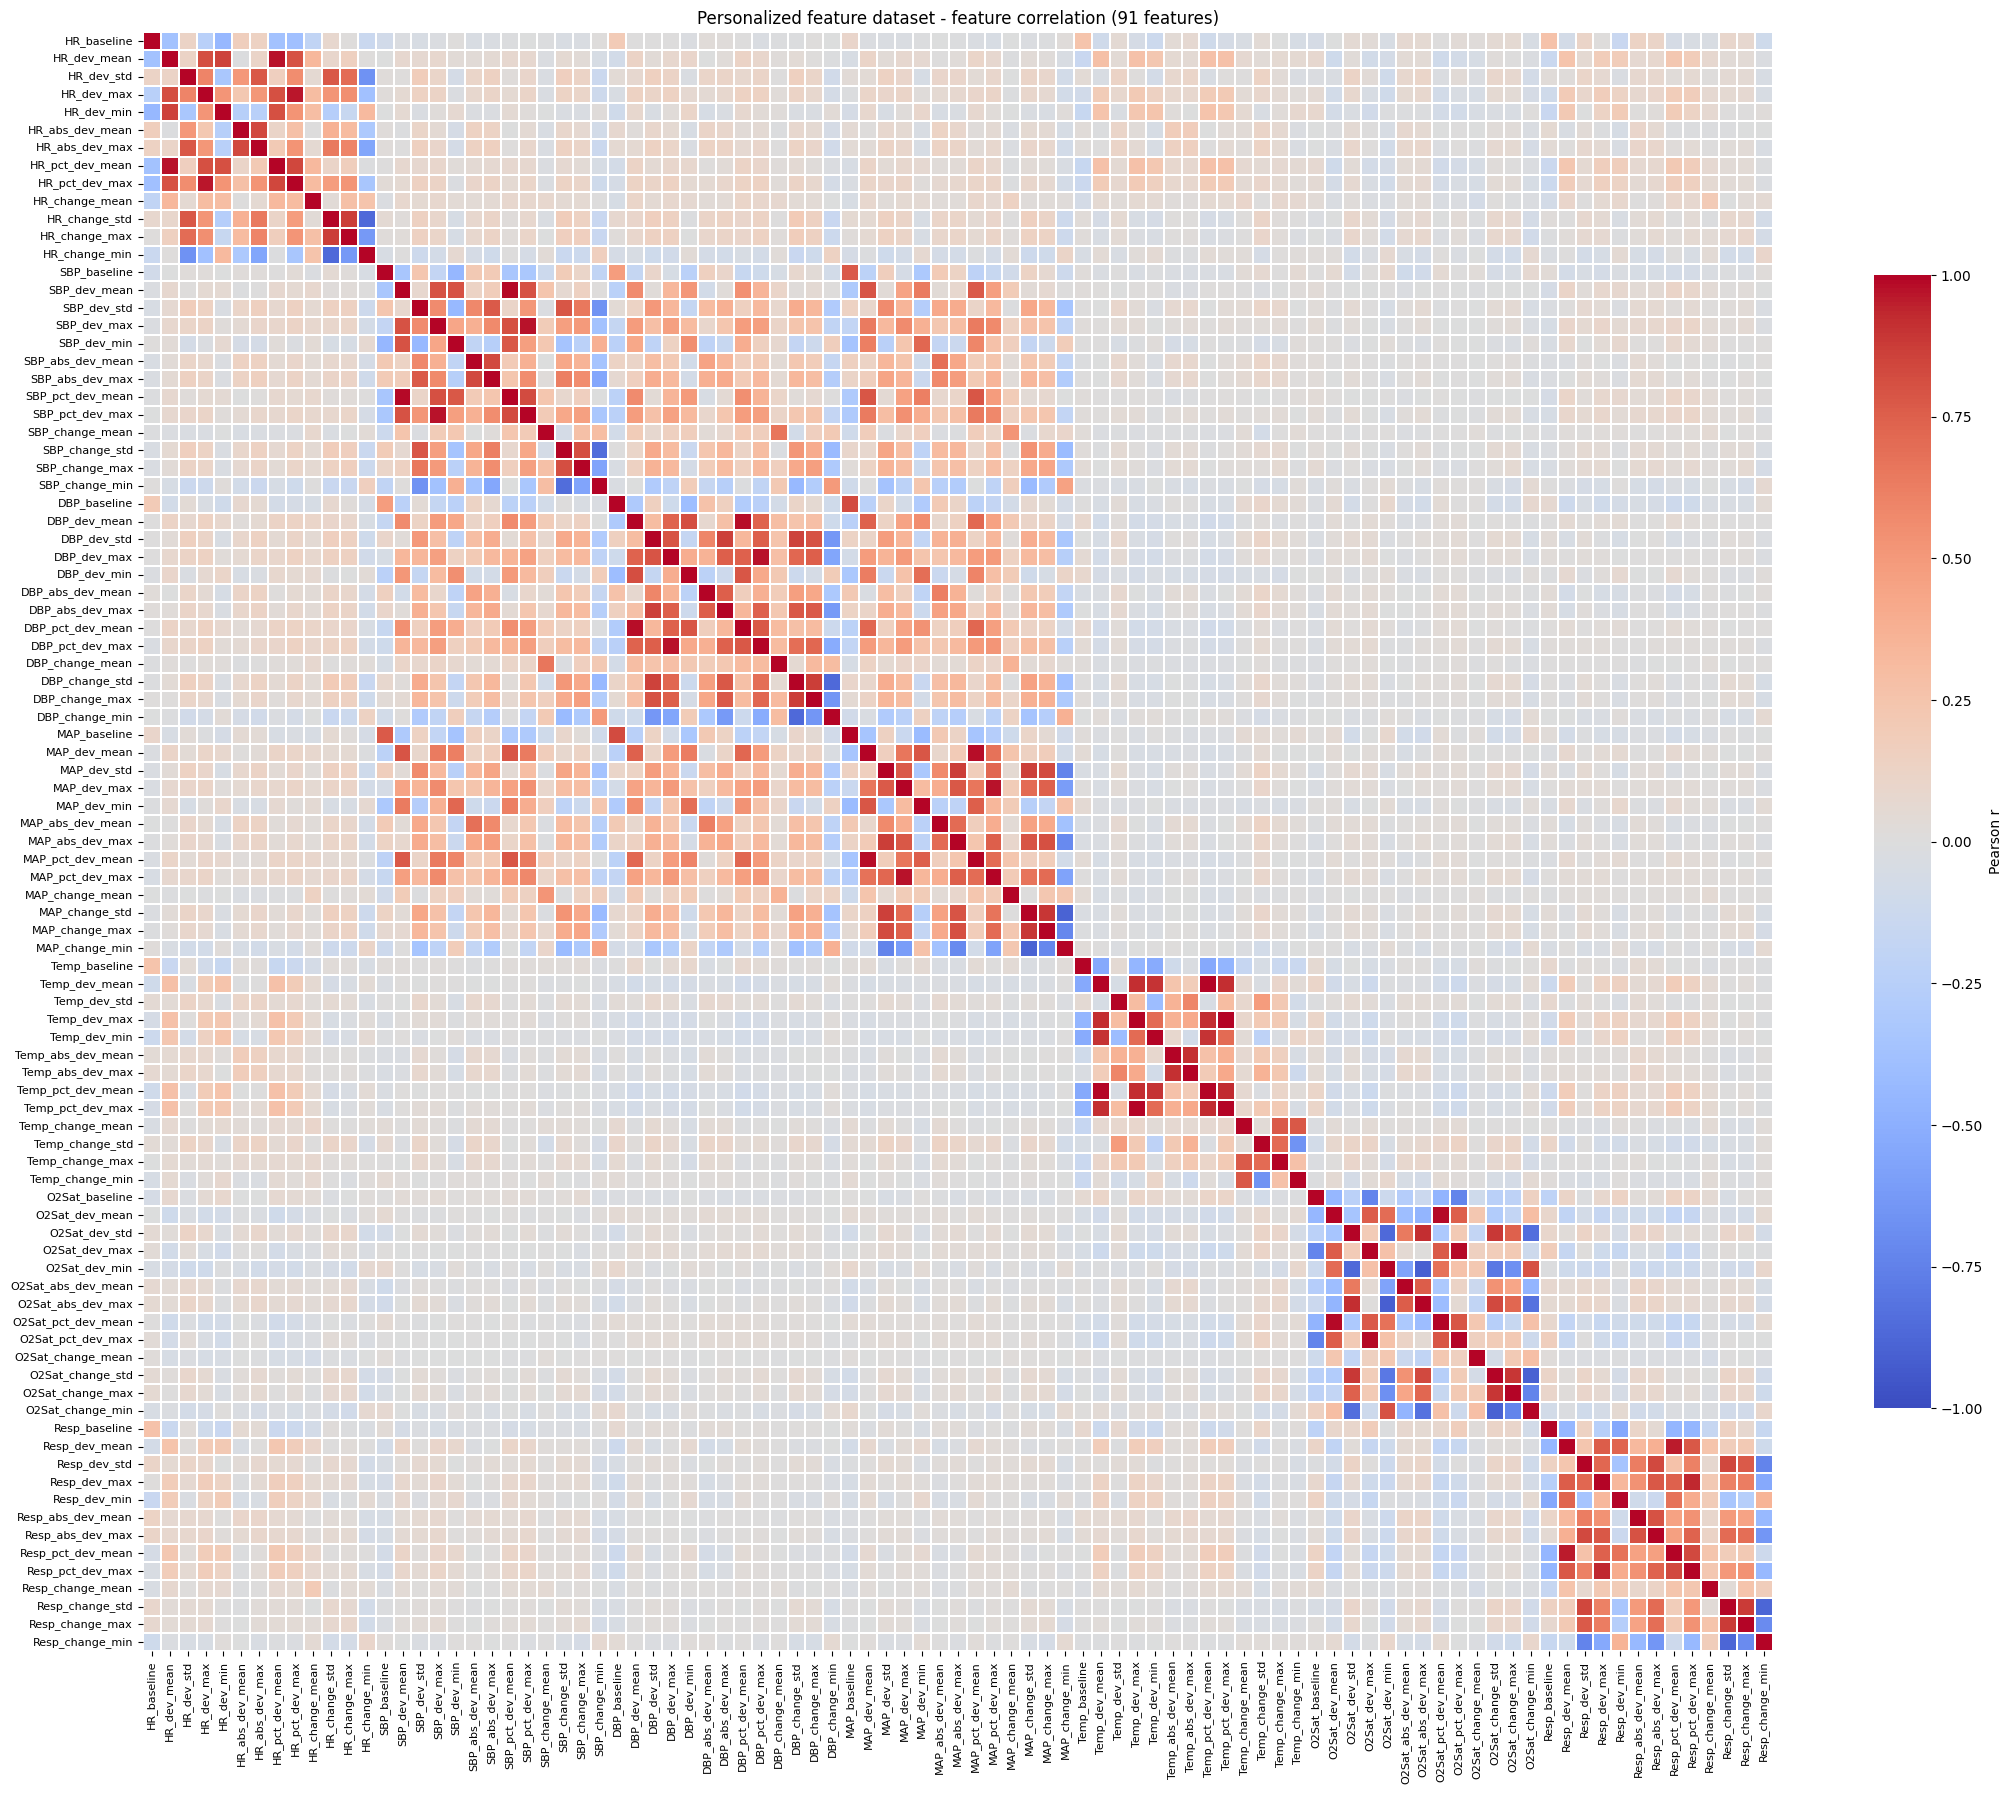

Top correlated pairs - Personalized


,Feature A,Feature B,|r|
0,Temp_dev_max,Temp_pct_dev_max,1.000
1,Temp_dev_mean,Temp_pct_dev_mean,1.000
2,O2Sat_dev_mean,O2Sat_pct_dev_mean,0.990
3,O2Sat_dev_max,O2Sat_pct_dev_max,0.988
4,SBP_dev_mean,SBP_pct_dev_mean,0.987
5,MAP_dev_mean,MAP_pct_dev_mean,0.980
6,DBP_dev_mean,DBP_pct_dev_mean,0.978
7,SBP_dev_max,SBP_pct_dev_max,0.976
8,MAP_dev_max,MAP_pct_dev_max,0.975
9,DBP_dev_max,DBP_pct_dev_max,0.971


In [71]:
# Correlation heatmaps: Conventional vs Personalized feature datasets

FEATURE_SETS = {
    'Conventional': conventional_features,
    'Personalized': patient_features,
}

corr_store = {}

for dname, dset in FEATURE_SETS.items():

    num = (
        dset
        .drop(columns=[patient_col])
        .select_dtypes(include=np.number)
    )

    corr = num.drop(columns=['Target']).corr()
    corr_store[dname] = num.corr()

    n = corr.shape[1]
    annot = n <= 20
    size = max(8, min(22, 0.55 * n))

    plt.figure(figsize=(size, size * 0.82))

    sns.heatmap(
        corr,
        cmap='coolwarm',
        vmin=-1, vmax=1,
        annot=annot,
        fmt='.2f',
        annot_kws={'size': 7},
        square=False,
        linewidths=0.3,
        cbar_kws={'shrink': 0.7, 'label': 'Pearson r'}
    )

    plt.title(f"{dname} feature dataset - feature correlation ({n} features)")
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

    # Strongest redundant pairs (|r| > 0.9), useful for interpreting the models later
    m = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = (
        m.stack()
         .sort_values(ascending=False)
         .head(10)
         .rename('|r|')
         .reset_index()
         .rename(columns={'level_0': 'Feature A', 'level_1': 'Feature B'})
    )
    print(f"Top correlated pairs - {dname}")
    display(pairs.round(3))

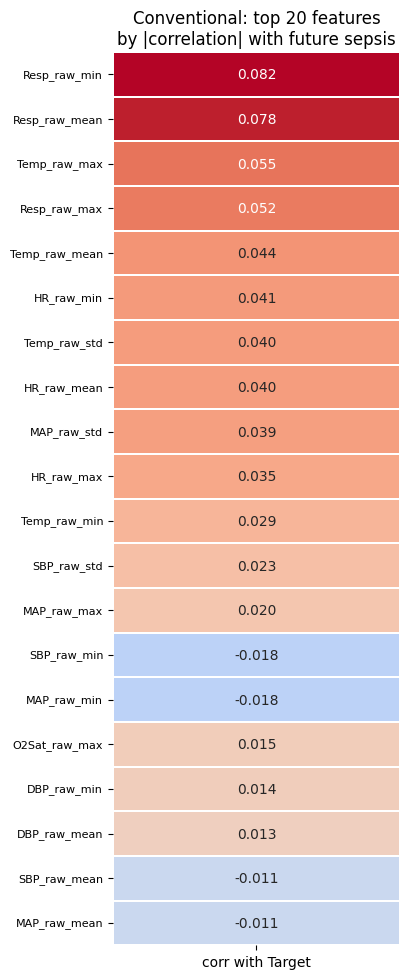

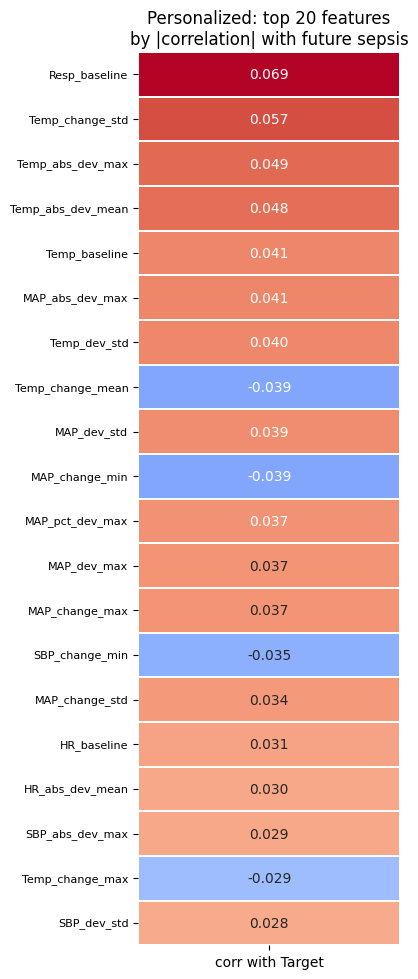

Strongest single-feature signal:
  Conventional  -> Resp_raw_min (r = +0.082)
  Personalized  -> Resp_baseline (r = +0.069)


In [72]:
# Heatmap of feature-vs-target correlation for both datasets, side by side

target_corr = {}

for dname, cm in corr_store.items():
    target_corr[dname] = (
        cm['Target']
        .drop(labels=['Target'])
        .sort_values(ascending=False)
    )

for dname, s in target_corr.items():

    top = s.reindex(s.abs().sort_values(ascending=False).index).head(20)

    plt.figure(figsize=(4.2, 0.42 * len(top) + 1.5))

    sns.heatmap(
        top.to_frame('corr with Target'),
        cmap='coolwarm',
        vmin=-max(0.05, top.abs().max()),
        vmax=max(0.05, top.abs().max()),
        annot=True,
        fmt='.3f',
        linewidths=0.3,
        cbar=False
    )

    plt.title(f"{dname}: top 20 features\nby |correlation| with future sepsis")
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

print("Strongest single-feature signal:")
for dname, s in target_corr.items():
    best = s.abs().idxmax()
    print(f"  {dname:13s} -> {best} (r = {s[best]:+.3f})")

In [53]:
# Train/test split for BOTH feature datasets - split BEFORE any resampling
from sklearn.model_selection import train_test_split

DATASETS = {
    'Conventional': conventional_features,   # raw 12-24 h summaries
    'Personalized': patient_features,        # patient-baseline deviation features
}

splits = {}

for dname, dset in DATASETS.items():
    Xd = dset.drop(columns=[patient_col, 'Target'])
    yd = dset['Target']

    Xtr, Xte, ytr, yte = train_test_split(
        Xd, yd, test_size=0.20, random_state=42, stratify=yd
    )

    splits[dname] = {'X_train': Xtr, 'X_test': Xte, 'y_train': ytr, 'y_test': yte}

    print(f"=== {dname} feature dataset ===")
    print("Features:", Xd.shape[1], "| Train:", Xtr.shape[0], "| Test:", Xte.shape[0])
    print("Train target distribution:", dict(ytr.value_counts()))
    print("Test  target distribution:", dict(yte.value_counts()))
    print("Positive rate: %.2f%%\n" % (yd.mean() * 100))

# Backwards-compatible aliases (personalized dataset)
X_train, X_test = splits['Personalized']['X_train'], splits['Personalized']['X_test']
y_train, y_test = splits['Personalized']['y_train'], splits['Personalized']['y_test']


=== Conventional feature dataset ===
Features: 28 | Train: 8485 | Test: 2122
Train target distribution: {0: np.int64(8233), 1: np.int64(252)}
Test  target distribution: {0: np.int64(2059), 1: np.int64(63)}
Positive rate: 2.97%

=== Personalized feature dataset ===
Features: 91 | Train: 8485 | Test: 2122
Train target distribution: {0: np.int64(8233), 1: np.int64(252)}
Test  target distribution: {0: np.int64(2059), 1: np.int64(63)}
Positive rate: 2.97%



In [54]:
# Handling class imbalance - computed separately for EACH dataset
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

for dname, s in splits.items():
    ytr = s['y_train']
    cw = compute_class_weight(class_weight='balanced', classes=classes, y=ytr)
    s['class_weight'] = dict(zip(classes, cw))

    neg, pos = (ytr == 0).sum(), (ytr == 1).sum()
    s['scale_pos_weight'] = neg / pos if pos > 0 else 1.0

    print(f"{dname}: class weights = { {k: round(v, 3) for k, v in s['class_weight'].items()} }, "
          f"scale_pos_weight = {s['scale_pos_weight']:.2f}")

# Imbalance is handled by (1) class weighting, (2) SMOTE inside .fit() only,
# (3) CV-tuned decision threshold. The test set of either dataset is NEVER resampled.
class_weight_dict = splits['Personalized']['class_weight']
scale_pos_weight = splits['Personalized']['scale_pos_weight']


Conventional: class weights = {np.int64(0): np.float64(0.515), np.int64(1): np.float64(16.835)}, scale_pos_weight = 32.67
Personalized: class weights = {np.int64(0): np.float64(0.515), np.int64(1): np.float64(16.835)}, scale_pos_weight = 32.67


## Class-imbalance handling + 12-model comparison on BOTH feature datasets

Two patient-level feature sets are modelled and compared head to head:

1. **Conventional features** - raw vital-sign summaries (mean/std/max/min) from the 12-24 h window.
2. **Personalized features** - deviations, percentage deviations and rates of change relative to each
   patient's own 0-12 h baseline.

Sepsis positives are a small minority of patients, so accuracy and ROC-AUC alone are misleading.
For **each dataset independently** the imbalance is handled three ways:

1. **Cost-sensitive learning** - `class_weight='balanced'` / `scale_pos_weight`, computed from that dataset's own training split.
2. **SMOTE oversampling** - applied *only inside the training fold*, never to the test set.
3. **Decision-threshold tuning** - the F1-optimal cut-off is learned by **CV on the training set only**, then applied once to the test set.

That gives **12 model families x 2 imbalance strategies x 2 datasets = 48 fitted models**, all compared on
**Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC and MCC**.

In [55]:
# Optional boosting libraries. Safe to skip if the environment has no internet.
!pip install -q xgboost lightgbm catboost 2>/dev/null || echo "install skipped - sklearn fallbacks will be used"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.6 MB/s eta 0:00:00


### SMOTE + pipeline helpers (no `imbalanced-learn` dependency)

`SMOTEPipeline` resamples inside `.fit()` only; `.predict()` / `.predict_proba()` never touch the resampler,
so the test set is always evaluated on real, unmodified data.

In [56]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import NearestNeighbors
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


def smote_oversample(X, y, k_neighbors=5, random_state=42):
    """Minimal SMOTE: oversample the minority class up to the majority count
    by interpolating between each minority point and one of its k nearest
    minority neighbors."""
    rng = np.random.RandomState(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    classes, counts = np.unique(y, return_counts=True)
    majority_count = counts.max()
    minority_class = classes[np.argmin(counts)]

    X_min = X[y == minority_class]
    n_needed = majority_count - len(X_min)

    if n_needed <= 0 or len(X_min) <= 1:
        return X, y

    k = min(k_neighbors, len(X_min) - 1)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
    _, neighbor_idx = nn.kneighbors(X_min)

    synthetic = np.zeros((n_needed, X.shape[1]))
    for i in range(n_needed):
        base_idx = rng.randint(0, len(X_min))
        neighbor = neighbor_idx[base_idx, rng.randint(1, k + 1)]
        gap = rng.rand()
        synthetic[i] = X_min[base_idx] + gap * (X_min[neighbor] - X_min[base_idx])

    X_res = np.vstack([X, synthetic])
    y_res = np.concatenate([y, np.full(n_needed, minority_class)])
    return X_res, y_res


class SMOTEPipeline(ClassifierMixin, BaseEstimator):
    """Stand-in for imblearn's Pipeline: SMOTE is applied to the training data
    only inside .fit(); .predict()/.predict_proba() skip it entirely."""

    def __init__(self, classifier, use_scaler=False, k_neighbors=5, random_state=42):
        self.classifier = classifier
        self.use_scaler = use_scaler
        self.k_neighbors = k_neighbors
        self.random_state = random_state

    def fit(self, X, y):
        self.imputer_ = SimpleImputer(strategy='median')
        Xt = self.imputer_.fit_transform(X)
        if self.use_scaler:
            self.scaler_ = StandardScaler()
            Xt = self.scaler_.fit_transform(Xt)
        Xr, yr = smote_oversample(Xt, np.asarray(y), self.k_neighbors, self.random_state)
        self.classifier.fit(Xr, yr)
        self.classes_ = np.unique(yr)
        self.is_fitted_ = True
        return self

    def _transform(self, X):
        Xt = self.imputer_.transform(X)
        if self.use_scaler:
            Xt = self.scaler_.transform(Xt)
        return Xt

    def predict(self, X):
        return self.classifier.predict(self._transform(X))

    def predict_proba(self, X):
        return self.classifier.predict_proba(self._transform(X))


def build_pipeline(classifier, use_scaler=False, use_smote=False):
    if use_smote:
        return SMOTEPipeline(classifier, use_scaler=use_scaler)
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if use_scaler:
        steps.append(('scaler', StandardScaler()))
    steps.append(('classifier', classifier))
    return Pipeline(steps)


### The 10 model families

In [57]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, BaggingClassifier, HistGradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

SEED = 42

HAS_XGB = HAS_LGBM = HAS_CAT = False
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except Exception: pass
try:
    from lightgbm import LGBMClassifier; HAS_LGBM = True
except Exception: pass
try:
    from catboost import CatBoostClassifier; HAS_CAT = True
except Exception: pass

print(f"xgboost={HAS_XGB}  lightgbm={HAS_LGBM}  catboost={HAS_CAT}")


def make_family(name):
    """Return (weighted_estimator, unweighted_estimator, needs_scaling) for a family.
    weighted_estimator = the cost-sensitive variant; unweighted = plain (used with SMOTE)."""
    if name == 'Logistic Regression':
        return (LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED),
                LogisticRegression(max_iter=3000, random_state=SEED), True)
    if name == 'Linear SVM':
        return (SGDClassifier(loss='modified_huber', class_weight='balanced', max_iter=3000, random_state=SEED),
                SGDClassifier(loss='modified_huber', max_iter=3000, random_state=SEED), True)
    if name == 'RBF SVM':
        return (SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED),
                SVC(kernel='rbf', probability=True, random_state=SEED), True)
    if name == 'Decision Tree':
        return (DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
                DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, random_state=SEED), False)
    if name == 'Random Forest':
        return (RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=4,
                                       class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
                RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=4,
                                       random_state=SEED, n_jobs=-1), False)
    if name == 'Extra Trees':
        return (ExtraTreesClassifier(n_estimators=400, max_depth=10, min_samples_leaf=3,
                                     class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
                ExtraTreesClassifier(n_estimators=400, max_depth=10, min_samples_leaf=3,
                                     random_state=SEED, n_jobs=-1), False)
    if name == 'KNN':
        # No class_weight: distance weighting is the closest cost-sensitive analogue.
        return (KNeighborsClassifier(n_neighbors=15, weights='distance'),
                KNeighborsClassifier(n_neighbors=15, weights='distance'), True)
    if name == 'Naive Bayes':
        # Cost sensitivity via class priors tilted toward the minority class.
        return (GaussianNB(priors=[0.5, 0.5]), GaussianNB(), True)
    if name == 'MLP':
        return (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, random_state=SEED),
                MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600, random_state=SEED), True)
    if name == 'Gradient Boosting':
        if HAS_XGB:
            return (XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                                  colsample_bytree=0.8, eval_metric='aucpr',
                                  scale_pos_weight=scale_pos_weight, random_state=SEED),
                    XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                                  colsample_bytree=0.8, eval_metric='aucpr', random_state=SEED), False)
        return (GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED),
                GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED), False)
    if name == 'Boosted Trees #2':
        if HAS_LGBM:
            return (LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                   class_weight='balanced', random_state=SEED, verbose=-1),
                    LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                   random_state=SEED, verbose=-1), False)
        if HAS_CAT:
            return (CatBoostClassifier(iterations=400, depth=6, learning_rate=0.05,
                                       auto_class_weights='Balanced', random_state=SEED, verbose=0),
                    CatBoostClassifier(iterations=400, depth=6, learning_rate=0.05,
                                       random_state=SEED, verbose=0), False)
        return (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                               class_weight='balanced', random_state=SEED),
                HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED), False)
    if name == 'AdaBoost':
        return (AdaBoostClassifier(
                    estimator=DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED),
                    n_estimators=300, learning_rate=0.05, random_state=SEED),
                AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=SEED),
                                   n_estimators=300, learning_rate=0.05, random_state=SEED), False)
    raise ValueError(name)


FAMILIES = [
    'Logistic Regression', 'Linear SVM', 'RBF SVM', 'Decision Tree', 'Random Forest',
    'Extra Trees', 'KNN', 'Naive Bayes', 'MLP', 'Gradient Boosting', 'Boosted Trees #2', 'AdaBoost',
]
print(len(FAMILIES), "model families")

xgboost=True  lightgbm=True  catboost=True
12 model families


### Build every model under both imbalance strategies

In [58]:
def build_all_models(spw):
    """Build every family under both imbalance strategies for a given
    negative/positive ratio (dataset specific)."""
    global scale_pos_weight
    scale_pos_weight = spw  # make_family reads this for XGBoost

    weighted_models, smote_models = {}, {}
    for fam in FAMILIES:
        weighted_est, plain_est, needs_scaling = make_family(fam)
        weighted_models[f'{fam} (weighted)'] = build_pipeline(weighted_est, use_scaler=needs_scaling)
        smote_models[f'{fam} (SMOTE)'] = build_pipeline(plain_est, use_scaler=needs_scaling, use_smote=True)
    return {**weighted_models, **smote_models}


print(f"{len(FAMILIES)} families x 2 imbalance strategies = {len(FAMILIES) * 2} models per dataset")
print(f"{len(FAMILIES) * 2 * len(splits)} fitted models in total across both datasets")


12 families x 2 imbalance strategies = 24 models per dataset
48 fitted models in total across both datasets


### Fit, tune the threshold on training data only, and evaluate

For every model the decision threshold is chosen by **stratified 5-fold CV on the training set**
(maximising F1 on out-of-fold predictions) and only then applied to the untouched test set.
The 0.5-threshold score is reported alongside so the gain from tuning is visible.

In [59]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report, precision_recall_curve, roc_curve
)


def best_f1_threshold(y_true, y_prob):
    p, r, thr = precision_recall_curve(y_true, y_prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    if len(thr) == 0:
        return 0.5
    return float(thr[int(np.argmax(f1[:-1]))])


def score(dataset, name, strategy, y_true, y_pred, y_prob, threshold):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Dataset': dataset,
        'Model': name,
        'Strategy': strategy,
        'Threshold': round(threshold, 3),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

all_rows, default_rows = [], []
fitted_models, test_probs = {}, {}   # keyed by (dataset, model)

for dname, s in splits.items():
    Xtr, Xte, ytr, yte = s['X_train'], s['X_test'], s['y_train'], s['y_test']
    print(f"\n########## {dname} feature dataset ##########")

    for name, pipe in build_all_models(s['scale_pos_weight']).items():
        strategy = 'SMOTE' if '(SMOTE)' in name else 'Class weights'
        try:
            # 1) threshold learned on the TRAINING set only (out-of-fold predictions)
            oof = cross_val_predict(clone(pipe), Xtr, ytr, cv=cv,
                                    method='predict_proba', n_jobs=1)[:, 1]
            thr = best_f1_threshold(ytr, oof)

            # 2) refit on full training set, evaluate once on the untouched test set
            pipe.fit(Xtr, ytr)
            prob = pipe.predict_proba(Xte)[:, 1]

            all_rows.append(score(dname, name, strategy, yte, (prob >= thr).astype(int), prob, thr))
            default_rows.append(score(dname, name, strategy, yte, (prob >= 0.5).astype(int), prob, 0.5))
            fitted_models[(dname, name)] = pipe
            test_probs[(dname, name)] = prob
            print(f"OK   {name:38s} thr={thr:.3f}")
        except Exception as e:
            print(f"FAIL {name:38s} {type(e).__name__}: {e}")

all_results = (pd.DataFrame(all_rows)
               .sort_values(['Dataset', 'PR-AUC', 'F1'], ascending=[True, False, False])
               .reset_index(drop=True))
default_df = pd.DataFrame(default_rows)

print(f"\n{len(all_results)} fitted models evaluated across {len(splits)} datasets.")

for dname in splits:
    print(f"\n===== {dname} feature dataset - ranked by PR-AUC =====")
    display(all_results[all_results['Dataset'] == dname]
            .drop(columns='Dataset')
            .reset_index(drop=True)
            .round(4))

# Alias kept for the personalized dataset
results_df = all_results[all_results['Dataset'] == 'Personalized'].reset_index(drop=True)



########## Conventional feature dataset ##########
OK   Logistic Regression (weighted)         thr=0.665
OK   Linear SVM (weighted)                  thr=0.707
OK   RBF SVM (weighted)                     thr=0.034
OK   Decision Tree (weighted)               thr=0.741
OK   Random Forest (weighted)               thr=0.296
OK   Extra Trees (weighted)                 thr=0.436
OK   KNN (weighted)                         thr=0.061
OK   Naive Bayes (weighted)                 thr=0.932
OK   MLP (weighted)                         thr=0.029
OK   Gradient Boosting (weighted)           thr=0.163
OK   Boosted Trees #2 (weighted)            thr=0.092
FAIL AdaBoost (weighted)                    ValueError: BaseClassifier in AdaBoostClassifier ensemble is worse than random, ensemble can not be fit.
OK   Logistic Regression (SMOTE)            thr=0.762
OK   Linear SVM (SMOTE)                     thr=0.975
OK   RBF SVM (SMOTE)                        thr=0.645
OK   Decision Tree (SMOTE)                 

,Model,Strategy,Threshold,Accuracy,Balanced Acc,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,RBF SVM (weighted),Class weights,0.034,0.7333,0.6087,0.0533,0.4762,0.0958,0.0835,0.6337,0.0775,30,533,33,1526
1,Gradient Boosting (weighted),Class weights,0.163,0.8600,0.5663,0.0602,0.2540,0.0973,0.0679,0.6669,0.0710,16,250,47,1809
2,Extra Trees (weighted),Class weights,0.436,0.7488,0.6244,0.0583,0.4921,0.1042,0.0974,0.6789,0.0695,31,501,32,1558
3,Gradient Boosting (SMOTE),SMOTE,0.100,0.8360,0.6154,0.0721,0.3810,0.1212,0.1077,0.6735,0.0654,24,309,39,1750
4,Naive Bayes (weighted),Class weights,0.932,0.9072,0.5752,0.0864,0.2222,0.1244,0.0961,0.6949,0.0640,14,148,49,1911
5,Random Forest (weighted),Class weights,0.296,0.7403,0.6431,0.0612,0.5397,0.1099,0.1105,0.6937,0.0629,34,522,29,1537
6,Boosted Trees #2 (SMOTE),SMOTE,0.023,0.7469,0.6388,0.0611,0.5238,0.1095,0.1082,0.6819,0.0621,33,507,30,1552
7,Random Forest (SMOTE),SMOTE,0.461,0.8332,0.5909,0.0631,0.3333,0.1061,0.0848,0.7021,0.0584,21,312,42,1747
8,Boosted Trees #2 (weighted),Class weights,0.092,0.9180,0.5577,0.0827,0.1746,0.1122,0.0808,0.6773,0.0579,11,122,52,1937
9,Logistic Regression (weighted),Class weights,0.665,0.9072,0.5752,0.0864,0.2222,0.1244,0.0961,0.6471,0.0571,14,148,49,1911



===== Personalized feature dataset - ranked by PR-AUC =====


,Model,Strategy,Threshold,Accuracy,Balanced Acc,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,RBF SVM (weighted),Class weights,0.035,0.7549,0.5891,0.0511,0.4127,0.0909,0.0708,0.6014,0.0768,26,483,37,1576
1,Boosted Trees #2 (SMOTE),SMOTE,0.066,0.9364,0.5210,0.0610,0.0794,0.0690,0.0370,0.6332,0.0649,5,77,58,1982
2,Gradient Boosting (SMOTE),SMOTE,0.069,0.8402,0.5484,0.0490,0.2381,0.0813,0.0468,0.6038,0.0592,15,291,48,1768
3,Gradient Boosting (weighted),Class weights,0.103,0.8907,0.5590,0.0667,0.2063,0.1008,0.0693,0.6692,0.0582,13,182,50,1877
4,RBF SVM (SMOTE),SMOTE,0.020,0.8940,0.5453,0.0598,0.1746,0.0891,0.0546,0.5857,0.0573,11,173,52,1886
5,Random Forest (weighted),Class weights,0.288,0.7974,0.6032,0.0600,0.3968,0.1042,0.0882,0.6514,0.0569,25,392,38,1667
6,MLP (SMOTE),SMOTE,0.004,0.8874,0.5419,0.0556,0.1746,0.0843,0.0489,0.5740,0.0510,11,187,52,1872
7,Boosted Trees #2 (weighted),Class weights,0.009,0.8011,0.5667,0.0501,0.3175,0.0866,0.0579,0.6408,0.0497,20,379,43,1680
8,MLP (weighted),Class weights,0.000,0.8440,0.5734,0.0592,0.2857,0.0981,0.0711,0.5801,0.0491,18,286,45,1773
9,Logistic Regression (weighted),Class weights,0.714,0.8954,0.5076,0.0351,0.0952,0.0513,0.0094,0.6086,0.0429,6,165,57,1894


### Comparison across datasets, models and imbalance strategies

Accuracy is reported because it was requested, but with only a few percent positives a do-nothing model
already scores ~97% - so read it next to **Precision, Recall, ROC-AUC and PR-AUC**.

In [60]:
# --- Comparison 1: accuracy / precision / recall / F1 / ROC-AUC side by side ---
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'MCC']

side_by_side = all_results.pivot_table(
    index=['Model', 'Strategy'], columns='Dataset',
    values=['Accuracy', 'Precision', 'Recall', 'ROC-AUC', 'PR-AUC']
).round(4)
print("Conventional vs Personalized features, per model:")
display(side_by_side)

# --- Comparison 2: how much do personalized features gain over conventional? ---
gain = (all_results.pivot_table(index='Model', columns='Dataset', values='ROC-AUC')
        .assign(**{'ROC-AUC gain': lambda d: d['Personalized'] - d['Conventional']})
        .sort_values('ROC-AUC gain', ascending=False).round(4))
print("\nPersonalized minus Conventional (ROC-AUC):")
display(gain)

# --- Comparison 3: imbalance strategy effect, per dataset ---
print("\nAverage performance by dataset x imbalance strategy:")
display(all_results.groupby(['Dataset', 'Strategy'])[metric_cols].mean().round(4))

# --- Comparison 4: tuned threshold vs default 0.5 ---
tuned_vs_default = all_results[['Dataset', 'Model', 'Recall', 'F1', 'Precision']].merge(
    default_df[['Dataset', 'Model', 'Recall', 'F1', 'Precision']].rename(
        columns={'Recall': 'Recall@0.5', 'F1': 'F1@0.5', 'Precision': 'Precision@0.5'}),
    on=['Dataset', 'Model'])
print("\nCV-tuned threshold vs default 0.5:")
display(tuned_vs_default.round(4))


Conventional vs Personalized features, per model:


Accuracy               \
Dataset                                      Conventional Personalized   
Model                          Strategy                                  
AdaBoost (SMOTE)               SMOTE               0.8412       0.9081   
AdaBoost (weighted)            Class weights          NaN       0.8751   
Boosted Trees #2 (SMOTE)       SMOTE               0.7469       0.9364   
Boosted Trees #2 (weighted)    Class weights       0.9180       0.8011   
Decision Tree (SMOTE)          SMOTE               0.7158       0.6701   
Decision Tree (weighted)       Class weights       0.8690       0.7964   
Extra Trees (SMOTE)            SMOTE               0.9317       0.7630   
Extra Trees (weighted)         Class weights       0.7488       0.9274   
Gradient Boosting (SMOTE)      SMOTE               0.8360       0.8402   
Gradient Boosting (weighted)   Class weights       0.8600       0.8907   
KNN (SMOTE)                    SMOTE               0.8355       0.2366   
KNN (weighted)                 Class weights       0.7413       0.9425   
Linear SVM (SMOTE)             SMOTE               0.9529       0.9020   
Linear SVM (weighted)          Class weights       0.6117       0.5900   
Logistic Regression (SMOTE)    SMOTE               0.9472       0.9043   
Logistic Regression (weighted) Class weights       0.9072       0.8954   
MLP (SMOTE)                    SMOTE               0.9274       0.8874   
MLP (weighted)                 Class weights       0.9109       0.8440   
Naive Bayes (SMOTE)            SMOTE               0.9524       0.9552   
Naive Bayes (weighted)         Class weights       0.9072       0.7747   
RBF SVM (SMOTE)                SMOTE               0.9062       0.8940   
RBF SVM (weighted)             Class weights       0.7333       0.7549   
Random Forest (SMOTE)          SMOTE               0.8332       0.8558   
Random Forest (weighted)       Class weights       0.7403       0.7974   

                                                   PR-AUC               \
Dataset                                      Conventional Personalized   
Model                          Strategy                                  
AdaBoost (SMOTE)               SMOTE               0.0506       0.0336   
AdaBoost (weighted)            Class weights          NaN       0.0389   
Boosted Trees #2 (SMOTE)       SMOTE               0.0621       0.0649   
Boosted Trees #2 (weighted)    Class weights       0.0579       0.0497   
Decision Tree (SMOTE)          SMOTE               0.0418       0.0292   
Decision Tree (weighted)       Class weights       0.0450       0.0391   
Extra Trees (SMOTE)            SMOTE               0.0566       0.0368   
Extra Trees (weighted)         Class weights       0.0695       0.0418   
Gradient Boosting (SMOTE)      SMOTE               0.0654       0.0592   
Gradient Boosting (weighted)   Class weights       0.0710       0.0582   
KNN (SMOTE)                    SMOTE               0.0459       0.0336   
KNN (weighted)                 Class weights       0.0544       0.0344   
Linear SVM (SMOTE)             SMOTE               0.0400       0.0410   
Linear SVM (weighted)          Class weights       0.0317       0.0346   
Logistic Regression (SMOTE)    SMOTE               0.0569       0.0399   
Logistic Regression (weighted) Class weights       0.0571       0.0429   
MLP (SMOTE)                    SMOTE               0.0360       0.0510   
MLP (weighted)                 Class weights       0.0354       0.0491   
Naive Bayes (SMOTE)            SMOTE               0.0570       0.0277   
Naive Bayes (weighted)         Class weights       0.0640       0.0391   
RBF SVM (SMOTE)                SMOTE               0.0423       0.0573   
RBF SVM (weighted)             Class weights       0.0775       0.0768   
Random Forest (SMOTE)          SMOTE               0.0584       0.0330   
Random Forest (weighted)       Class weights       0.0629       0.0569   

                                                Pre


Personalized minus Conventional (ROC-AUC):


Dataset,Conventional,Personalized,ROC-AUC gain
Model,,,
MLP (weighted),0.5348,0.5801,0.0453
MLP (SMOTE),0.5370,0.5740,0.0370
Linear SVM (weighted),0.5314,0.5623,0.0309
RBF SVM (SMOTE),0.5660,0.5857,0.0197
Gradient Boosting (weighted),0.6669,0.6692,0.0023
Decision Tree (weighted),0.5740,0.5513,-0.0226
RBF SVM (weighted),0.6337,0.6014,-0.0322
Boosted Trees #2 (weighted),0.6773,0.6408,-0.0365
Logistic Regression (SMOTE),0.6382,0.6008,-0.0375



Average performance by dataset x imbalance strategy:


Accuracy  Precision  Recall      F1  ROC-AUC  \
Dataset      Strategy                                                      
Conventional Class weights    0.8134     0.0640  0.3348  0.1018   0.6289   
             SMOTE            0.8689     0.0621  0.2262  0.0845   0.6242   
Personalized Class weights    0.8241     0.0464  0.2500  0.0740   0.5968   
             SMOTE            0.8128     0.0429  0.2077  0.0633   0.5493   

                            PR-AUC     MCC  
Dataset      Strategy                       
Conventional Class weights  0.0569  0.0786  
             SMOTE          0.0511  0.0601  
Personalized Class weights  0.0468  0.0420  
             SMOTE          0.0423  0.0234


CV-tuned threshold vs default 0.5:


,Dataset,Model,Recall,F1,Precision,Recall@0.5,F1@0.5,Precision@0.5
0,Conventional,RBF SVM (weighted),0.4762,0.0958,0.0533,0.0000,0.0000,0.0000
1,Conventional,Gradient Boosting (weighted),0.2540,0.0973,0.0602,0.0317,0.0460,0.0833
2,Conventional,Extra Trees (weighted),0.4921,0.1042,0.0583,0.1111,0.0933,0.0805
3,Conventional,Gradient Boosting (SMOTE),0.3810,0.1212,0.0721,0.0159,0.0247,0.0556
4,Conventional,Naive Bayes (weighted),0.2222,0.1244,0.0864,0.4127,0.1051,0.0602
5,Conventional,Random Forest (weighted),0.5397,0.1099,0.0612,0.0000,0.0000,0.0000
6,Conventional,Boosted Trees #2 (SMOTE),0.5238,0.1095,0.0611,0.0000,0.0000,0.0000
7,Conventional,Random Forest (SMOTE),0.3333,0.1061,0.0631,0.2540,0.1056,0.0667
8,Conventional,Boosted Trees #2 (weighted),0.1746,0.1122,0.0827,0.0000,0.0000,0.0000
9,Conventional,Logistic Regression (weighted),0.2222,0.1244,0.0864,0.6032,0.1016,0.0555


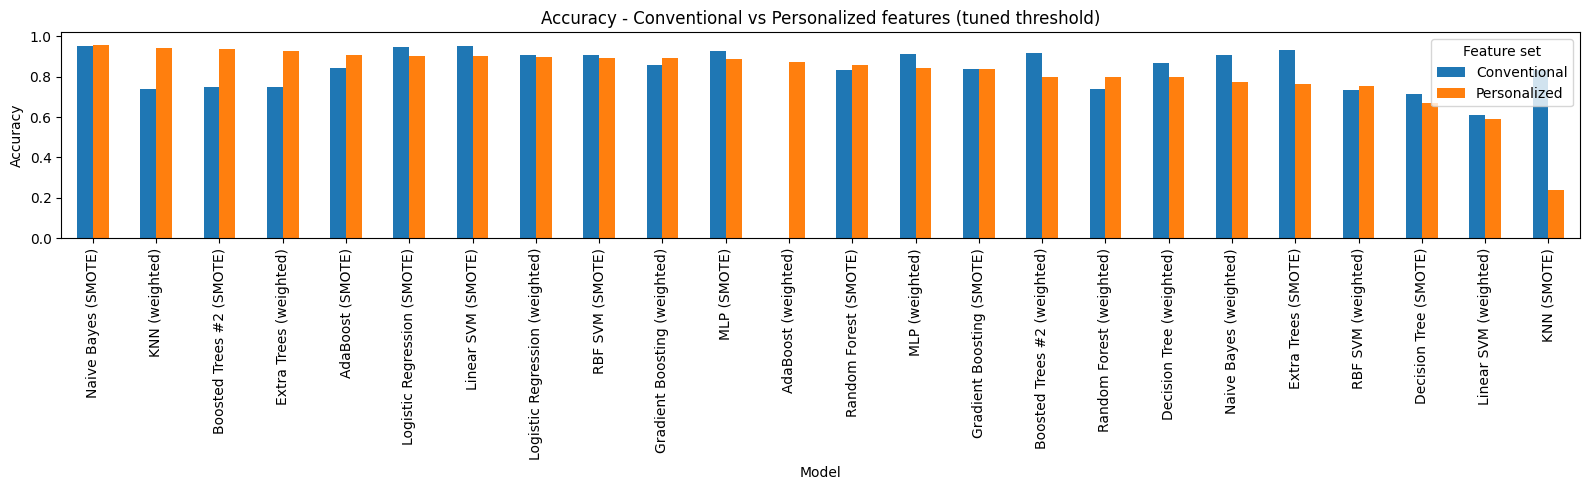

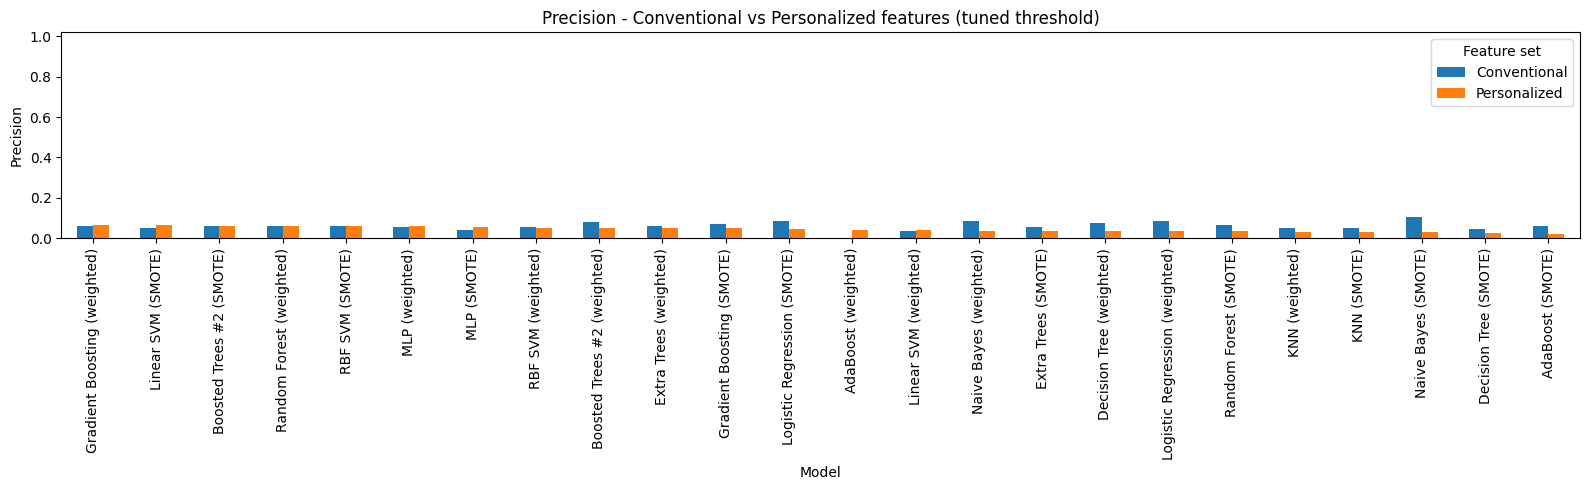

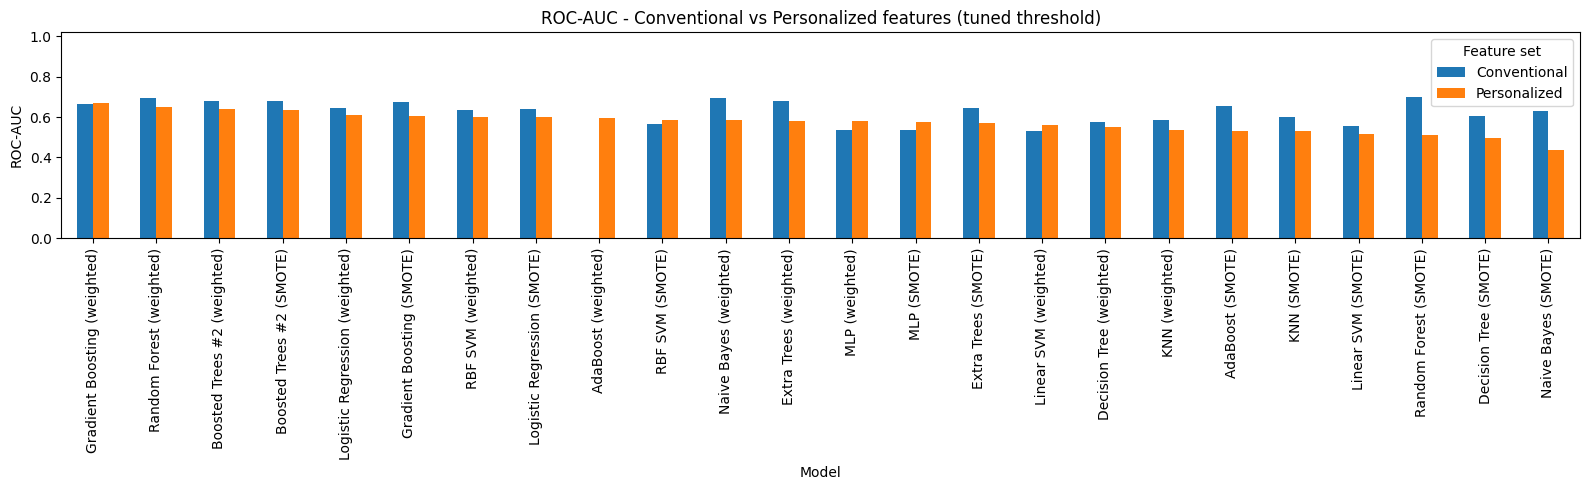

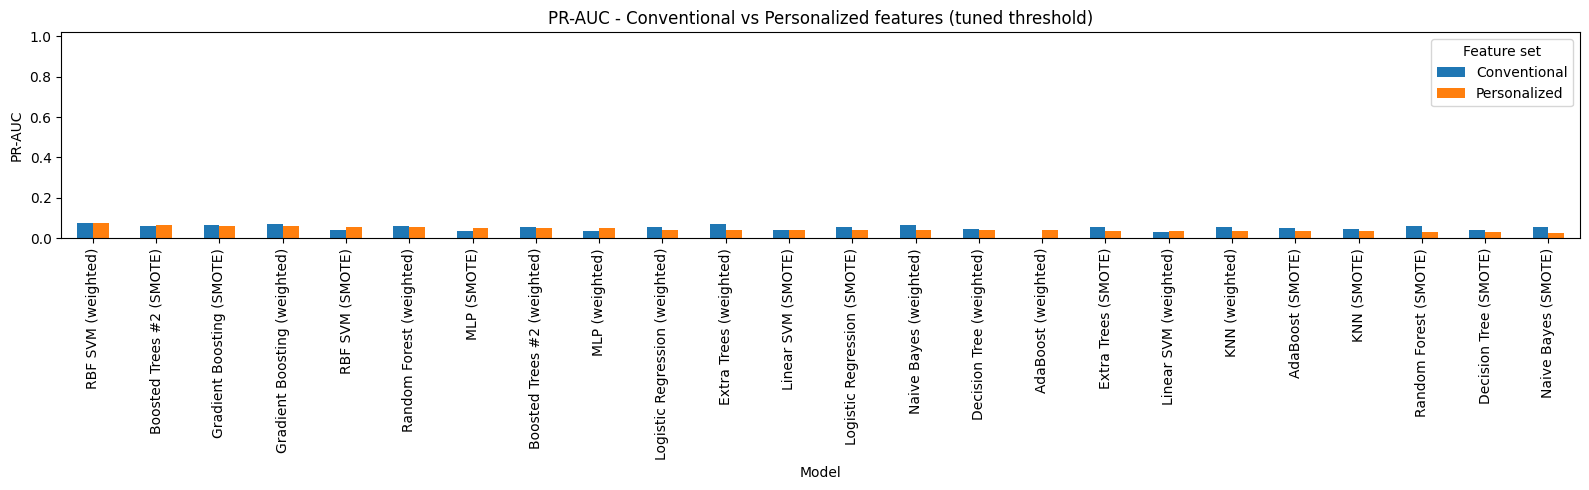

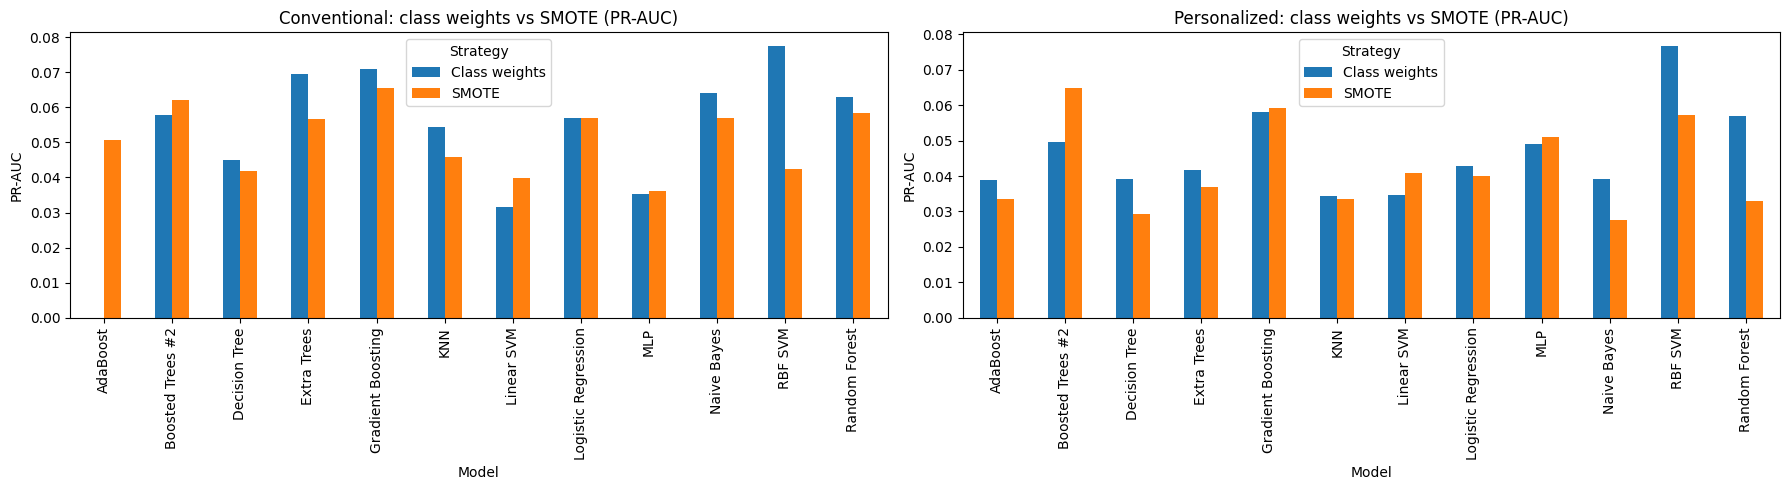

In [61]:
# Bar charts: every model, both datasets, key metrics
for metric in ['Accuracy', 'Precision', 'ROC-AUC', 'PR-AUC']:
    pivot = all_results.pivot_table(index='Model', columns='Dataset', values=metric)
    pivot = pivot.sort_values('Personalized', ascending=False)

    ax = pivot.plot(kind='bar', figsize=(16, 5))
    ax.set_title(f"{metric} - Conventional vs Personalized features (tuned threshold)")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.02)
    ax.tick_params(axis='x', rotation=90)
    ax.legend(title='Feature set')
    plt.tight_layout()
    plt.show()

# Class weighting vs SMOTE within each dataset
fig, axes = plt.subplots(1, len(splits), figsize=(9 * len(splits), 5), squeeze=False)
for ax, dname in zip(axes[0], splits):
    sub = all_results[all_results['Dataset'] == dname]
    piv = sub.pivot_table(
        index=sub['Model'].str.replace(r' \((weighted|SMOTE)\)', '', regex=True),
        columns='Strategy', values='PR-AUC')
    piv.plot(kind='bar', ax=ax)
    ax.set_title(f"{dname}: class weights vs SMOTE (PR-AUC)")
    ax.set_ylabel("PR-AUC")
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()


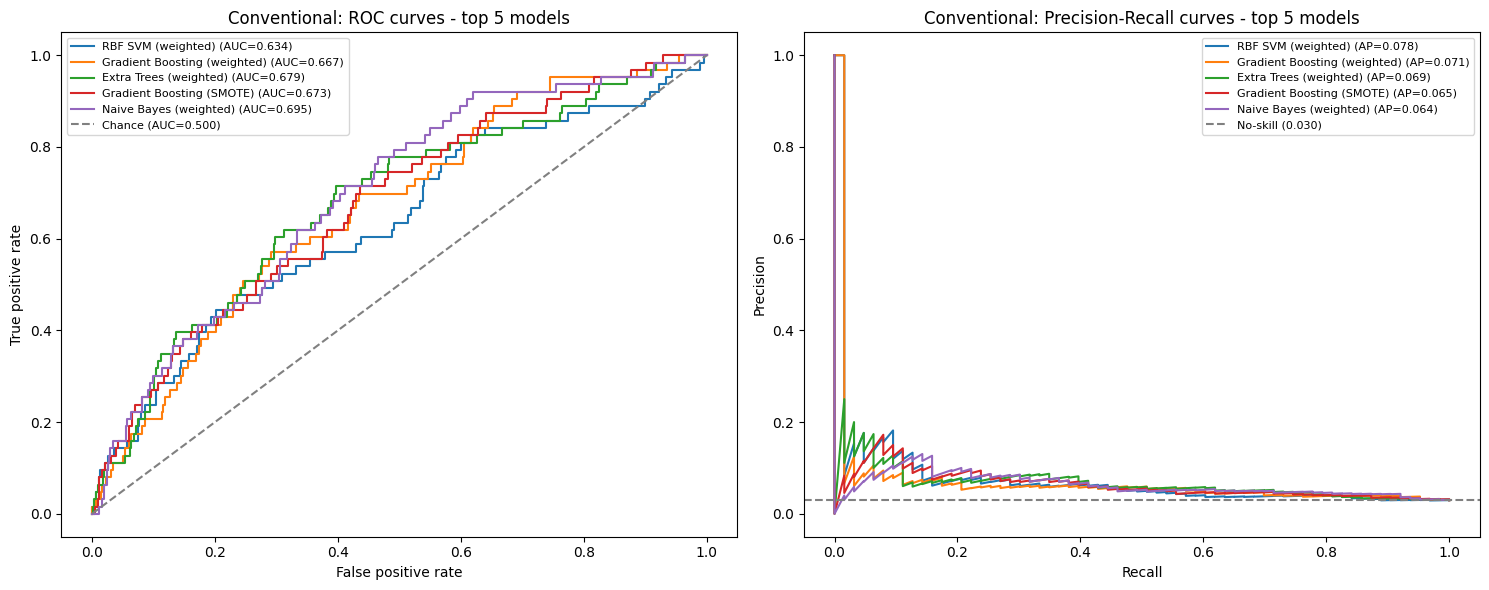

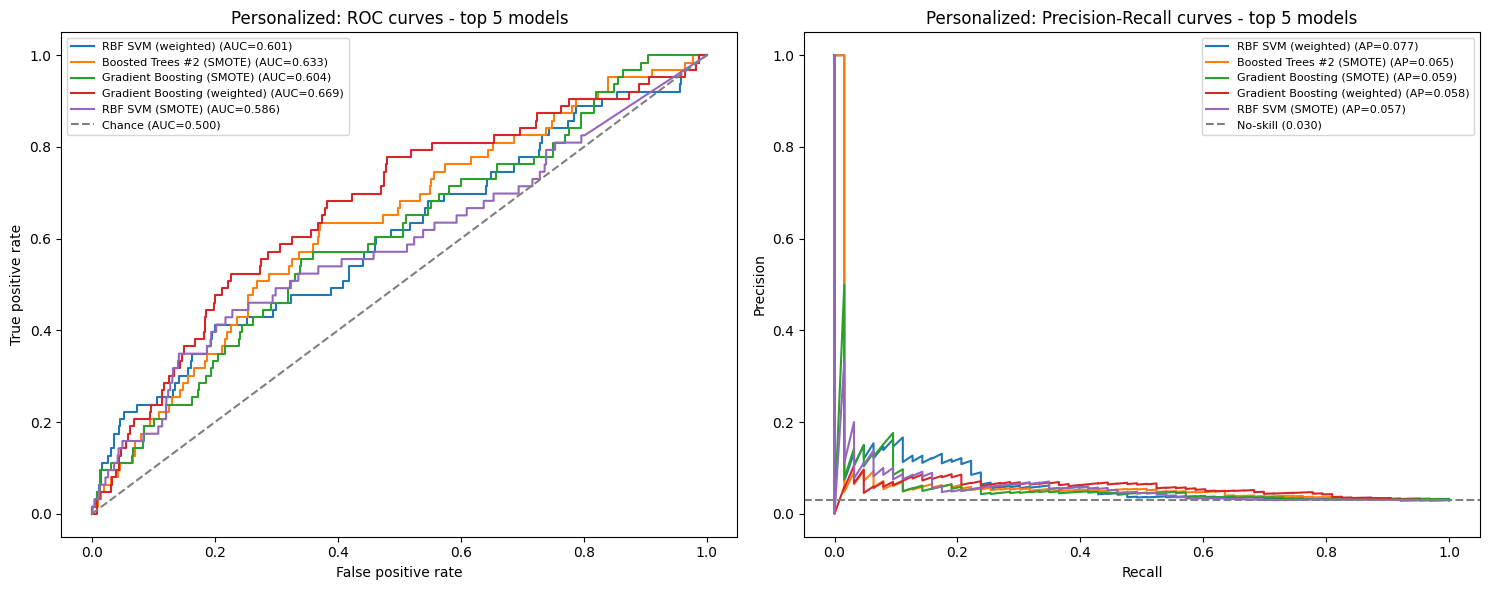

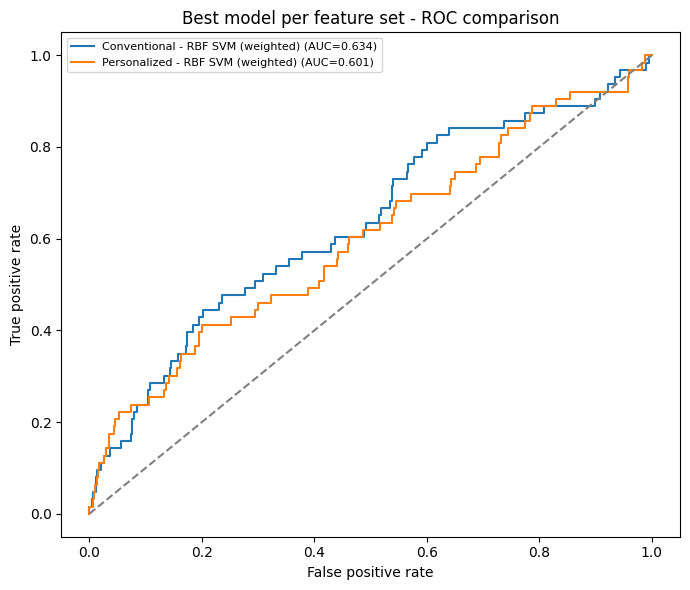

In [62]:
# ROC and Precision-Recall curves for the top 5 models of each dataset
for dname, s in splits.items():
    yte = s['y_test']
    top5 = all_results[all_results['Dataset'] == dname]['Model'].head(5)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for name in top5:
        prob = test_probs[(dname, name)]
        fpr, tpr, _ = roc_curve(yte, prob)
        axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yte, prob):.3f})")

        p, r, _ = precision_recall_curve(yte, prob)
        axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(yte, prob):.3f})")

    axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Chance (AUC=0.500)')
    axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
    axes[0].set_title(f"{dname}: ROC curves - top 5 models"); axes[0].legend(fontsize=8)

    axes[1].axhline(yte.mean(), linestyle='--', color='grey',
                    label=f"No-skill ({yte.mean():.3f})")
    axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
    axes[1].set_title(f"{dname}: Precision-Recall curves - top 5 models"); axes[1].legend(fontsize=8)

    plt.tight_layout(); plt.show()

# Best model of each dataset on one ROC plot
plt.figure(figsize=(7, 6))
for dname, s in splits.items():
    best = all_results[all_results['Dataset'] == dname].iloc[0]['Model']
    prob = test_probs[(dname, best)]
    fpr, tpr, _ = roc_curve(s['y_test'], prob)
    plt.plot(fpr, tpr, label=f"{dname} - {best} (AUC={roc_auc_score(s['y_test'], prob):.3f})")
plt.plot([0, 1], [0, 1], '--', color='grey')
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Best model per feature set - ROC comparison")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()


### Best model of each feature dataset in detail

In [63]:
for dname, s in splits.items():
    yte = s['y_test']
    best_row = all_results[all_results['Dataset'] == dname].iloc[0]
    best_name = best_row['Model']
    best_prob = test_probs[(dname, best_name)]
    best_thr = best_row['Threshold']

    print("#" * 70)
    print(f"{dname} feature dataset - best model by PR-AUC: {best_name}")
    print(f"Imbalance strategy : {best_row['Strategy']}")
    print(f"CV-tuned threshold : {best_thr:.3f} (default would be 0.500)")
    print(f"Accuracy={best_row['Accuracy']:.4f}  Precision={best_row['Precision']:.4f}  "
          f"Recall={best_row['Recall']:.4f}  ROC-AUC={best_row['ROC-AUC']:.4f}  "
          f"PR-AUC={best_row['PR-AUC']:.4f}\n")

    for label, thr in [("default 0.50", 0.5), (f"tuned {best_thr:.2f}", best_thr)]:
        pred = (best_prob >= thr).astype(int)
        print("=" * 60)
        print(f"{best_name} @ {label}")
        print("=" * 60)
        print(classification_report(yte, pred, zero_division=0))
        print("Confusion matrix [[TN FP] [FN TP]]:")
        print(confusion_matrix(yte, pred, labels=[0, 1]), "\n")


######################################################################
Conventional feature dataset - best model by PR-AUC: RBF SVM (weighted)
Imbalance strategy : Class weights
CV-tuned threshold : 0.034 (default would be 0.500)
Accuracy=0.7333  Precision=0.0533  Recall=0.4762  ROC-AUC=0.6337  PR-AUC=0.0775

RBF SVM (weighted) @ default 0.50
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      2059
           1       0.00      0.00      0.00        63

    accuracy                           0.97      2122
   macro avg       0.49      0.50      0.49      2122
weighted avg       0.94      0.97      0.96      2122

Confusion matrix [[TN FP] [FN TP]]:
[[2059    0]
 [  63    0]] 

RBF SVM (weighted) @ tuned 0.03
              precision    recall  f1-score   support

           0       0.98      0.73      0.84      2059
           1       0.05      0.48      0.09        63

    accuracy                           0.72      2122
   macro avg 

### Takeaways to write up

- Imbalance is handled **identically and independently** on both feature sets (class weights, SMOTE inside `.fit()`, CV-tuned threshold), so the conventional-vs-personalized comparison is fair.
- Report **Precision / Recall / F1 / ROC-AUC / PR-AUC / MCC**, never accuracy alone.
- The `ROC-AUC gain` table shows, per model, how much the patient-specific baseline features add over conventional raw summaries.
- Neither test set is ever resampled or used to pick a threshold.

### **Champion selection: best model per feature dataset**<br><br>
For each feature dataset the champion is the model with the highest test PR-AUC (ties broken by F1), since PR-AUC is the most informative metric under strong class imbalance. Both champions were selected with an untouched test set and a threshold tuned only on training-fold predictions.


In [65]:
# --- Best (champion) model of EACH feature dataset ---
champions = {}
champion_rows = []

for dname in splits:
    sub = (all_results[all_results['Dataset'] == dname]
           .sort_values(['PR-AUC', 'F1'], ascending=False))
    row = sub.iloc[0]
    champions[dname] = {
        'model': row['Model'],
        'strategy': row['Strategy'],
        'threshold': float(row['Threshold']),
        'prob': test_probs[(dname, row['Model'])],
        'y_test': splits[dname]['y_test'],
        'pipeline': fitted_models[(dname, row['Model'])],
        'row': row,
    }
    champion_rows.append(row)
    runner = sub.iloc[1] if len(sub) > 1 else None
    print(f"{dname:13s} champion: {row['Model']} [{row['Strategy']}]"
          f"  PR-AUC={row['PR-AUC']:.4f}  ROC-AUC={row['ROC-AUC']:.4f}  F1={row['F1']:.4f}")
    if runner is not None:
        print(f"{'':13s} runner-up: {runner['Model']} (PR-AUC={runner['PR-AUC']:.4f}, "
              f"margin={row['PR-AUC'] - runner['PR-AUC']:+.4f})")

champions_df = (pd.DataFrame(champion_rows)
                .set_index('Dataset')[['Model', 'Strategy', 'Threshold', 'Accuracy',
                                       'Balanced Acc', 'Precision', 'Recall', 'F1',
                                       'MCC', 'ROC-AUC', 'PR-AUC', 'TP', 'FP', 'FN', 'TN']]
                .round(4))
print("\nChampion of each feature dataset:")
display(champions_df)

Conventional  champion: RBF SVM (weighted) [Class weights]  PR-AUC=0.0775  ROC-AUC=0.6337  F1=0.0958
              runner-up: Gradient Boosting (weighted) (PR-AUC=0.0710, margin=+0.0065)
Personalized  champion: RBF SVM (weighted) [Class weights]  PR-AUC=0.0768  ROC-AUC=0.6014  F1=0.0909
              runner-up: Boosted Trees #2 (SMOTE) (PR-AUC=0.0649, margin=+0.0118)

Champion of each feature dataset:


,Model,Strategy,Threshold,Accuracy,Balanced Acc,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN
Dataset,,,,,,,,,,,,,,,
Conventional,RBF SVM (weighted),Class weights,0.034,0.7333,0.6087,0.0533,0.4762,0.0958,0.0835,0.6337,0.0775,30,533,33,1526
Personalized,RBF SVM (weighted),Class weights,0.035,0.7549,0.5891,0.0511,0.4127,0.0909,0.0708,0.6014,0.0768,26,483,37,1576


# **Best vs best: head-to-head between the two champions**
The conventional champion and the personalized champion are compared on the same held-out patients: metric-by-metric deltas, overlaid ROC / PR curves, confusion matrices, and statistical tests (bootstrap CI on the PR-AUC / ROC-AUC difference plus McNemar on the thresholded decisions).

In [67]:
# --- Head-to-head metric comparison of the two champions ---
A_name, B_name = 'Conventional', 'Personalized'
A, B = champions[A_name], champions[B_name]

h2h_metrics = ['Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1', 'MCC', 'ROC-AUC', 'PR-AUC']
h2h = pd.DataFrame({
    f"{A_name}: {A['model']}": [A['row'][m] for m in h2h_metrics],
    f"{B_name}: {B['model']}": [B['row'][m] for m in h2h_metrics],
}, index=h2h_metrics)
h2h['Difference (Pers - Conv)'] = h2h.iloc[:, 1] - h2h.iloc[:, 0]
h2h['Winner'] = np.where(h2h['Difference (Pers - Conv)'] > 0, B_name,
                  np.where(h2h['Difference (Pers - Conv)'] < 0, A_name, 'Tie'))
print("BEST vs BEST - champion of each feature dataset on the held-out test set:")
display(h2h.round(4))

wins = (h2h['Winner'] == B_name).sum(), (h2h['Winner'] == A_name).sum()
print(f"\nMetric wins -> {B_name}: {wins[0]} | {A_name}: {wins[1]} | ties: "
      f"{len(h2h) - sum(wins)}")

# Error counts at each champion's own tuned threshold
for tag, C in [(A_name, A), (B_name, B)]:
    pred = (C['prob'] >= C['threshold']).astype(int)
    print("\n" + "=" * 64)
    print(f"{tag} champion: {C['model']} @ threshold {C['threshold']:.3f}")
    print("=" * 64)
    print(classification_report(C['y_test'], pred, zero_division=0))
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(confusion_matrix(C['y_test'], pred, labels=[0, 1]))

BEST vs BEST - champion of each feature dataset on the held-out test set:


,Conventional: RBF SVM (weighted),Personalized: RBF SVM (weighted),Difference (Pers - Conv),Winner
Accuracy,0.7333,0.7549,0.0217,Personalized
Balanced Acc,0.6087,0.5891,-0.0196,Conventional
Precision,0.0533,0.0511,-0.0022,Conventional
Recall,0.4762,0.4127,-0.0635,Conventional
F1,0.0958,0.0909,-0.0049,Conventional
MCC,0.0835,0.0708,-0.0127,Conventional
ROC-AUC,0.6337,0.6014,-0.0322,Conventional
PR-AUC,0.0775,0.0768,-0.0008,Conventional



Metric wins -> Personalized: 1 | Conventional: 7 | ties: 0

Conventional champion: RBF SVM (weighted) @ threshold 0.034
              precision    recall  f1-score   support

           0       0.98      0.73      0.84      2059
           1       0.05      0.48      0.09        63

    accuracy                           0.72      2122
   macro avg       0.52      0.60      0.47      2122
weighted avg       0.95      0.72      0.82      2122

Confusion matrix [[TN FP] [FN TP]]:
[[1507  552]
 [  33   30]]

Personalized champion: RBF SVM (weighted) @ threshold 0.035
              precision    recall  f1-score   support

           0       0.98      0.76      0.86      2059
           1       0.05      0.41      0.09        63

    accuracy                           0.75      2122
   macro avg       0.51      0.59      0.47      2122
weighted avg       0.95      0.75      0.83      2122

Confusion matrix [[TN FP] [FN TP]]:
[[1570  489]
 [  37   26]]


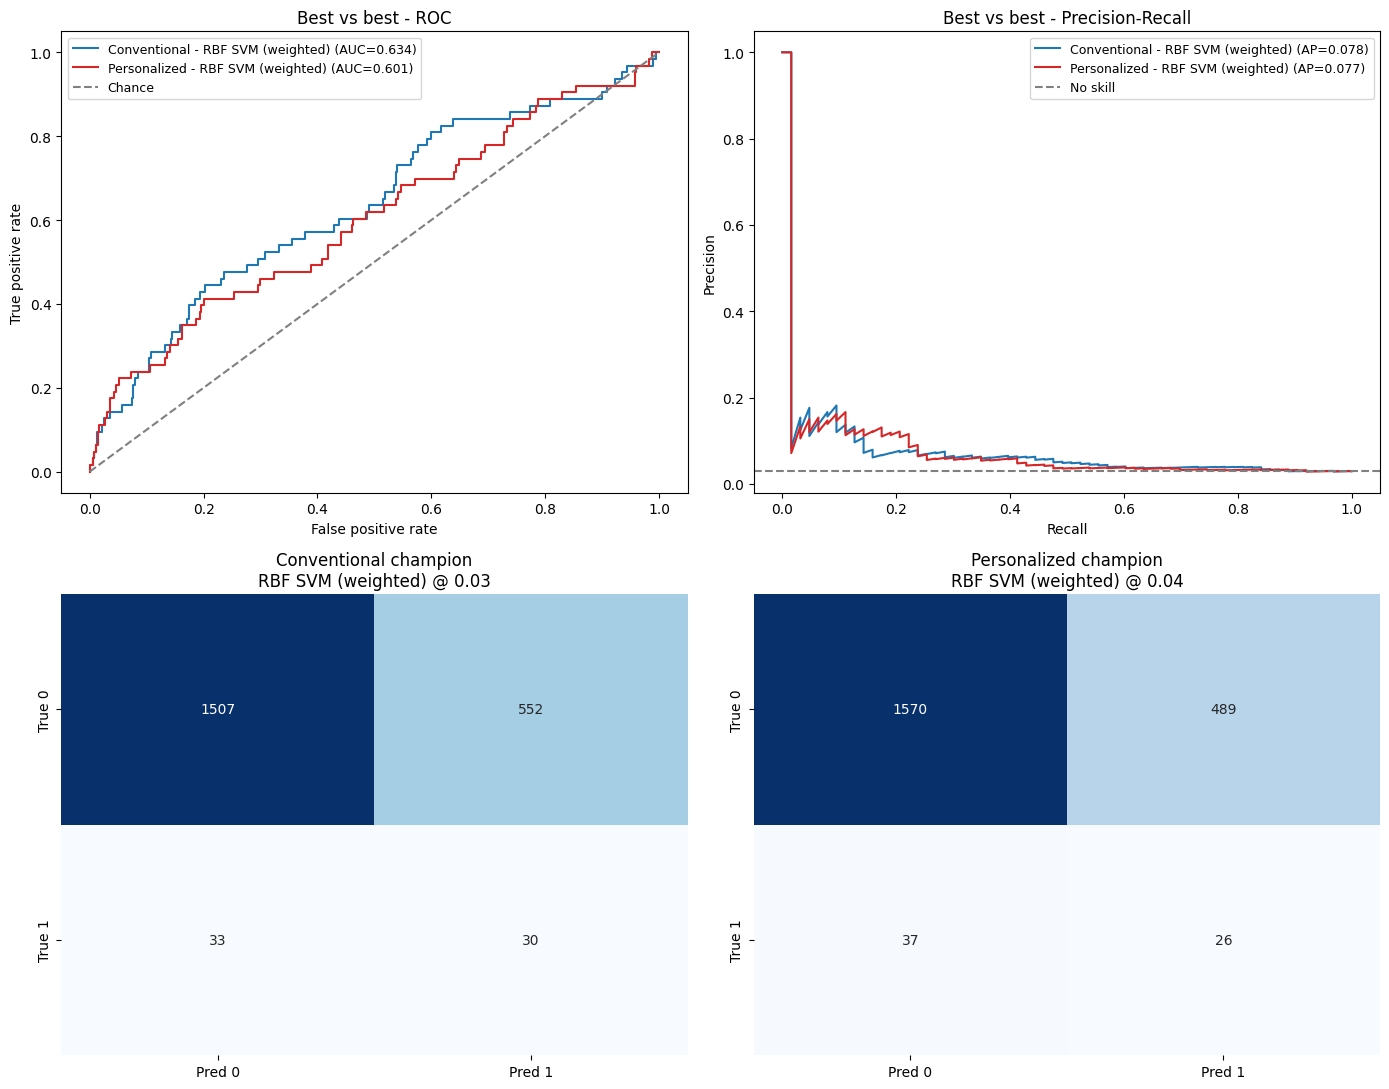

In [68]:
# --- Overlaid ROC and PR curves + confusion matrices for the two champions ---
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for tag, C, color in [(A_name, A, 'tab:blue'), (B_name, B, 'tab:red')]:
    fpr, tpr, _ = roc_curve(C['y_test'], C['prob'])
    axes[0, 0].plot(fpr, tpr, color=color,
                    label=f"{tag} - {C['model']} (AUC={roc_auc_score(C['y_test'], C['prob']):.3f})")
    p, r, _ = precision_recall_curve(C['y_test'], C['prob'])
    axes[0, 1].plot(r, p, color=color,
                    label=f"{tag} - {C['model']} (AP={average_precision_score(C['y_test'], C['prob']):.3f})")

axes[0, 0].plot([0, 1], [0, 1], '--', color='grey', label='Chance')
axes[0, 0].set_xlabel("False positive rate"); axes[0, 0].set_ylabel("True positive rate")
axes[0, 0].set_title("Best vs best - ROC"); axes[0, 0].legend(fontsize=9)

axes[0, 1].axhline(B['y_test'].mean(), linestyle='--', color='grey', label='No skill')
axes[0, 1].set_xlabel("Recall"); axes[0, 1].set_ylabel("Precision")
axes[0, 1].set_title("Best vs best - Precision-Recall"); axes[0, 1].legend(fontsize=9)

for ax, (tag, C) in zip(axes[1], [(A_name, A), (B_name, B)]):
    cm = confusion_matrix(C['y_test'], (C['prob'] >= C['threshold']).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    ax.set_title(f"{tag} champion\n{C['model']} @ {C['threshold']:.2f}")

plt.tight_layout(); plt.show()

In [70]:
# --- Statistical comparison of the two champions ---
rng = np.random.default_rng(SEED)

yA, yB = np.asarray(A['y_test']), np.asarray(B['y_test'])
pA, pB = np.asarray(A['prob']), np.asarray(B['prob'])

aligned = (len(yA) == len(yB)) and np.array_equal(
    np.asarray(A['y_test'].index), np.asarray(B['y_test'].index))
print("Test sets contain the same patients in the same order:", aligned)

def boot_ci(metric_fn, n_boot=2000):
    """Paired bootstrap of the (Personalized - Conventional) metric difference."""
    diffs = []
    n = len(yA)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(yA[idx])) < 2:
            continue
        diffs.append(metric_fn(yB[idx], pB[idx]) - metric_fn(yA[idx], pA[idx]))
    d = np.array(diffs)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), (d <= 0).mean()

if aligned:
    for label, fn in [('ROC-AUC', roc_auc_score), ('PR-AUC', average_precision_score)]:
        m, lo, hi, p_one_sided = boot_ci(fn)
        verdict = "significant" if lo > 0 or hi < 0 else "not significant"
        print(f"\n{label} difference (Personalized - Conventional): {m:+.4f}  "
              f"95% CI [{lo:+.4f}, {hi:+.4f}] -> {verdict}")
        print(f"  bootstrap one-sided p(Personalized <= Conventional) = {p_one_sided:.4f}")

    # McNemar test on the thresholded decisions
    from scipy.stats import binomtest
    predA = (pA >= A['threshold']).astype(int)
    predB = (pB >= B['threshold']).astype(int)
    correctA, correctB = (predA == yA), (predB == yB)
    b = int((~correctA & correctB).sum())   # only Personalized correct
    c = int((correctA & ~correctB).sum())   # only Conventional correct
    print(f"\nMcNemar discordant pairs -> only {B_name} correct: {b} | only {A_name} correct: {c}")
    if b + c > 0:
        print(f"McNemar exact p-value = {binomtest(b, b + c, 0.5).pvalue:.4f}")
    else:
        print("Both champions make identical decisions on every test patient.")
else:
    print("Test sets are not patient-aligned, so only unpaired metric values are comparable.")

# --- Final verdict ---
overall_winner = B_name if B['row']['PR-AUC'] >= A['row']['PR-AUC'] else A_name
loser = A_name if overall_winner == B_name else B_name
print("\n" + "#" * 70)
print(f"OVERALL WINNER: {overall_winner} features with {champions[overall_winner]['model']}")
print(f"  PR-AUC {champions[overall_winner]['row']['PR-AUC']:.4f} vs "
      f"{champions[loser]['row']['PR-AUC']:.4f} ({loser}: {champions[loser]['model']})")
print(f"  ROC-AUC {champions[overall_winner]['row']['ROC-AUC']:.4f} vs "
      f"{champions[loser]['row']['ROC-AUC']:.4f}")
print(f"  Recall {champions[overall_winner]['row']['Recall']:.4f} vs "
      f"{champions[loser]['row']['Recall']:.4f}")
print("#" * 70)

Test sets contain the same patients in the same order: True

ROC-AUC difference (Personalized - Conventional): -0.0325  95% CI [-0.1033, +0.0342] -> not significant
  bootstrap one-sided p(Personalized <= Conventional) = 0.8275

PR-AUC difference (Personalized - Conventional): -0.0012  95% CI [-0.0577, +0.0549] -> not significant
  bootstrap one-sided p(Personalized <= Conventional) = 0.5120

McNemar discordant pairs -> only Personalized correct: 339 | only Conventional correct: 280
McNemar exact p-value = 0.0197

######################################################################
OVERALL WINNER: Conventional features with RBF SVM (weighted)
  PR-AUC 0.0775 vs 0.0768 (Personalized: RBF SVM (weighted))
  ROC-AUC 0.6337 vs 0.6014
  Recall 0.4762 vs 0.4127
######################################################################
